In [ ]:
from google.colab import drive

drive.mount('/content/drive')
import os

PROJECT_PATH = "/content/drive/MyDrive/DeepLearning_TakeHome"
os.makedirs(PROJECT_PATH, exist_ok=True)

print("Project berhasil disiapkan!")
print("Lokasi:", PROJECT_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project berhasil disiapkan!
Lokasi: /content/drive/MyDrive/DeepLearning_TakeHome


In [ ]:
!pip install torch torchvision torchaudio
!pip install matplotlib seaborn
!pip install scikit-image torchmetrics torch-fidelity
!pip install pandas numpy tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 9.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [torch-fidelity]


In [8]:

import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split, ConcatDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

from tqdm.auto import tqdm

#Random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

#Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 128
LATENT_DIM = 64
EPOCHS = 20
LEARNING_RATE = 0.0002

print("Device:", device)
print("Batch Size:", BATCH_SIZE)
print("Latent Dimension:", LATENT_DIM)
print("Random Seed:", SEED)

Device: cuda
Batch Size: 128
Latent Dimension: 64
Random Seed: 42


In [ ]:
transform = transforms.ToTensor()

# Download Fashion-MNIST
train_dataset = datasets.FashionMNIST(
    root=PROJECT_PATH + "/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=PROJECT_PATH + "/data",
    train=False,
    download=True,
    transform=transform
)

#Gabungkan dataset agar bisa dibagi 80:10:10
full_dataset = ConcatDataset([
    train_dataset,
    test_dataset
])

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

train_set, val_set, test_set = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)

#DataLoader
train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Total Dataset:", total_size)
print("Training:", len(train_set))
print("Validation:", len(val_set))
print("Testing:", len(test_set))

Total Dataset: 70000
Training: 56000
Validation: 7000
Testing: 7000


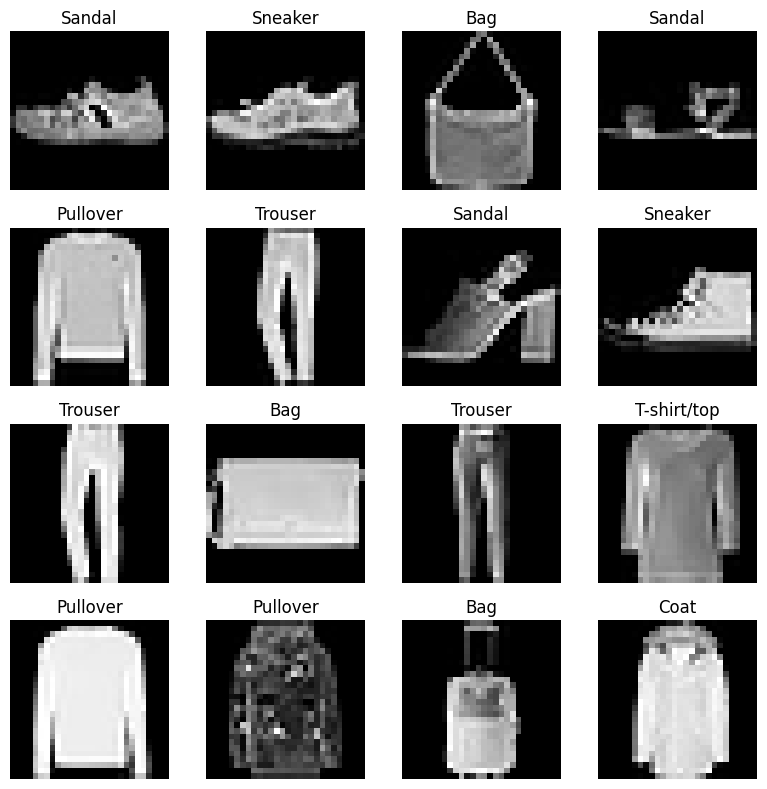

In [ ]:
#Nama kategorinya
classes = [
    "T-shirt/top", "Trouser", "Pullover",
    "Dress", "Coat", "Sandal",
    "Shirt", "Sneaker", "Bag", "Ankle boot"
]

images, labels = next(iter(train_loader))

#menampilkan 16 gambar
plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        images[i].squeeze(),
        cmap="gray"
    )

    plt.title(classes[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Membuat folder project
folders = [
    "src/models",
    "src/training",
    "src/evaluation",
    "src/utils",
    "checkpoints",
    "results/figures",
    "results/metrics",
    "results/generated_images"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_PATH, folder),
        exist_ok=True
    )

print("Struktur folder berhasil dibuat!")

Struktur folder berhasil dibuat!


# Vanilla Autoencoder

In [ ]:
#buat file autoencoder.py
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/autoencoder.py

import torch
import torch.nn as nn


class VanillaAutoencoder(nn.Module):

    def __init__(self, latent_dim=64):
        super(VanillaAutoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, latent_dim)
        )

        #decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),

            nn.Linear(128, 256),
            nn.ReLU(),

            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):

        #ubah gambar menjadi latent representation
        z = self.encoder(x)

        #mengembalikan latent representation menjadi gambar
        reconstructed = self.decoder(z)

        #ngubah bentuk menjadi [batch, 1, 28, 28]
        reconstructed = reconstructed.view(-1, 1, 28, 28)

        return reconstructed, z

Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/autoencoder.py


In [9]:
import sys
import time

#tambahin lokasi project ke Python path
sys.path.insert(0, PROJECT_PATH)

from src.models.autoencoder import VanillaAutoencoder

#model
model_ae = VanillaAutoencoder(
    latent_dim=LATENT_DIM
).to(device)

#loss function
criterion = nn.MSELoss()

#optimizer
optimizer = optim.Adam(
    model_ae.parameters(),
    lr=0.001
)

#riwayat training
history_ae = {
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}

#checkpoint
checkpoint_path = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "vanilla_ae.pth"
)

best_val_loss = float("inf")

#training
for epoch in range(EPOCHS):

    start_time = time.time()

    model_ae.train()

    total_train_loss = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        images = images.to(device)

        # Forward pass -> model mengahsilkan gambar rekonstruksi
        reconstructed, z = model_ae(images)

        # Hitung loss -> buat ngebandingin gambar asli dengan rekonstruksi
        loss = criterion(reconstructed, images)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    train_loss = total_train_loss / len(train_loader.dataset)

    #validation

    model_ae.eval()

    total_val_loss = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            reconstructed, z = model_ae(images)
            loss = criterion(reconstructed, images)
            total_val_loss += loss.item() * images.size(0)
    val_loss = total_val_loss / len(val_loader.dataset)

    #waktu per satu epoch
    epoch_time = time.time() - start_time

    #save riwayat
    history_ae["train_loss"].append(train_loss)
    history_ae["val_loss"].append(val_loss)
    history_ae["epoch_time"].append(epoch_time)

    #save model terbaik berdasarkan validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model_ae.state_dict(),
            checkpoint_path
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f} "
        f"Time: {epoch_time:.2f}s"
    )

print("Training Vanilla AE selesai!")
print("Best Validation Loss:", best_val_loss)

Epoch 1/20:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch [1/20] Train Loss: 0.039266 Val Loss: 0.023518 Time: 9.48s


Epoch 2/20:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch [2/20] Train Loss: 0.021053 Val Loss: 0.019520 Time: 8.31s


Epoch 3/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe4ff2c0900>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7fe4ff2c0900>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    self._shutdown_workers()if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

... (49 outputs left out)

Epoch [19/20] Train Loss: 0.009841 Val Loss: 0.010257 Time: 10.41s


Epoch 20/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe4ff2c0900>
    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    Exception ignored in: if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7fe4ff2c0900>

AssertionError: can only test a child process
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [20/20] Train Loss: 0.009698 Val Loss: 0.009995 Time: 10.20s
Training Vanilla AE selesai!
Best Validation Loss: 0.00999455999476569


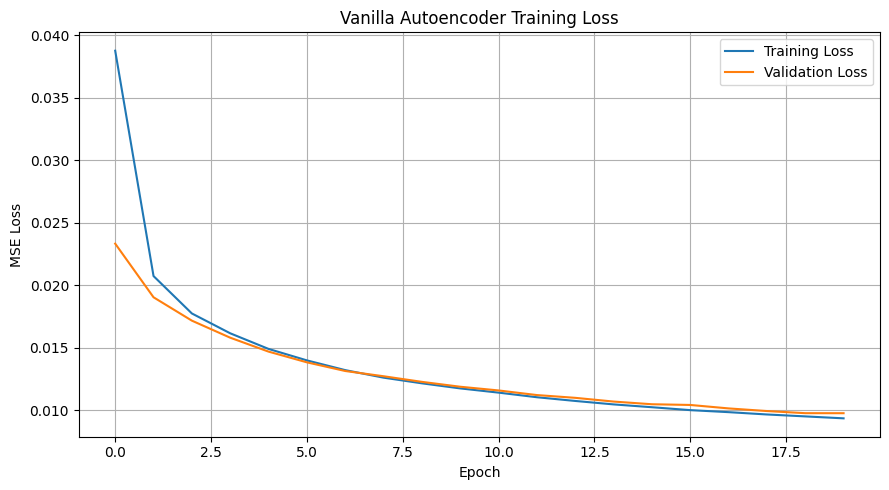

In [ ]:
#Plot training dan validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    history_ae["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_ae["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Vanilla Autoencoder Training Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

# Simpan grafik
plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vanilla_ae_loss.png"
    ),
    dpi=300
)
plt.show()

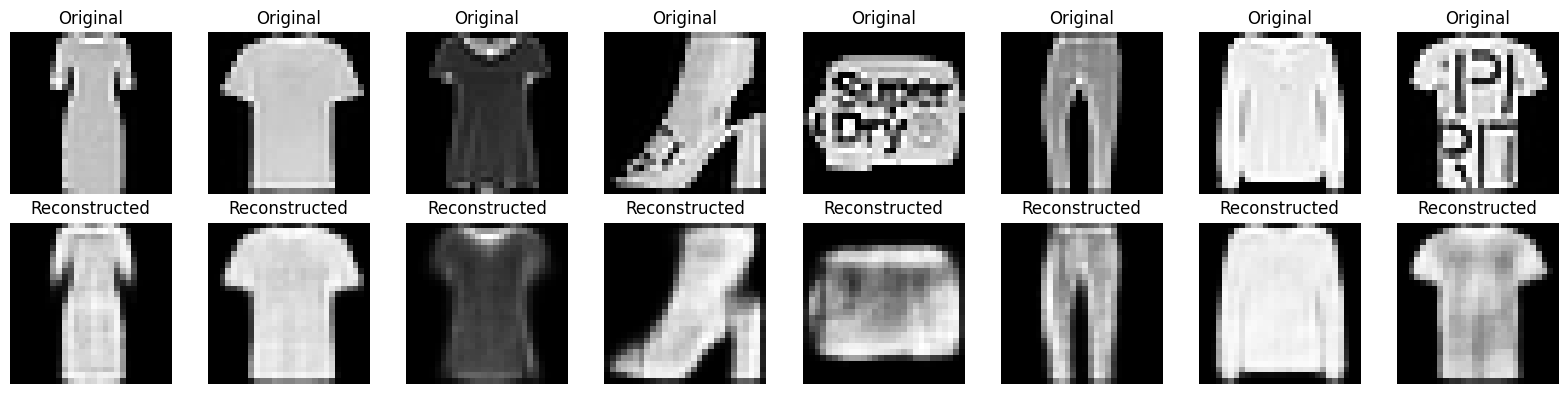

Latent shape: torch.Size([8, 64])


In [ ]:
#melihat hasil rekonstruksi gambar
#muat model terbaik
model_ae.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device
    )
)

model_ae.eval()

#get 8 gambar dari test set
images, labels = next(iter(test_loader))

images = images[:8].to(device)

#Rekonstruksi gambar
with torch.no_grad():

    reconstructed, latent = model_ae(images)

# Visualisasinya
fig, axes = plt.subplots(
    2, 8,
    figsize=(16, 4)
)

for i in range(8):

    # gambar asli
    axes[0, i].imshow(
        images[i].cpu().squeeze(),
        cmap="gray"
    )

    axes[0, i].set_title("Original")

    # gambar rekonstruksi
    axes[1, i].imshow(
        reconstructed[i].cpu().squeeze(),
        cmap="gray"
    )

    axes[1, i].set_title("Reconstructed")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vanilla_ae_reconstruction.png"
    ),
    dpi=300
)

plt.show()
print("Latent shape:", latent.shape)

# Spare Autoencoder

In [ ]:
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/sparse_autoencoder.py

import torch
import torch.nn as nn


class SparseAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super(SparseAutoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)

        reconstructed = self.decoder(z)
        reconstructed = reconstructed.view(-1, 1, 28, 28)

        return reconstructed, z

Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/sparse_autoencoder.py


In [ ]:
import sys
import time
import torch
import torch.nn as nn
import torch.optim as optim
import os

from tqdm.auto import tqdm

sys.path.insert(0, PROJECT_PATH)

from src.models.sparse_autoencoder import SparseAutoencoder

#konfigurasi
LATENT_DIM = 64
LAMBDA_SPARSITY = 0.0001
EPOCHS = 20
LEARNING_RATE = 0.001

#modelnya
model_sparse = SparseAutoencoder(
    latent_dim=LATENT_DIM
).to(device)

#optimizer
optimizer_sparse = optim.Adam(
    model_sparse.parameters(),
    lr=LEARNING_RATE
)

#Losss function
criterion = nn.MSELoss()

# riwayat training
history_sparse = {
    "train_loss": [],
    "val_loss": [],
    "reconstruction_loss": [],
    "sparsity_loss": [],
    "epoch_time": []
}

#checkpoint
checkpoint_sparse = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "sparse_ae.pth"
)

best_val_loss_sparse = float("inf")

print("Sparse Autoencoder berhasil dibuat!")
print("Device:", device)
print("Lambda Sparsity:", LAMBDA_SPARSITY)

Sparse Autoencoder berhasil dibuat!
Device: cuda
Lambda Sparsity: 0.0001


In [ ]:
for epoch in range(EPOCHS):
    start_time = time.time()
    #training
    model_sparse.train()

    total_train_loss = 0
    total_reconstruction_loss = 0
    total_sparsity_loss = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images = images.to(device)
        # Forward pass
        reconstructed, z = model_sparse(images)
        # Reconstruction loss
        reconstruction_loss = criterion(
            reconstructed,
            images
        )
        # Sparsity loss: rata-rata jumlah aktivasi absolut
        sparsity_loss = torch.mean(
            torch.sum(torch.abs(z), dim=1)
        )
        # Total loss

        loss = (
            reconstruction_loss
            + LAMBDA_SPARSITY * sparsity_loss
        )
        # Backpropagation
        optimizer_sparse.zero_grad()
        loss.backward()
        optimizer_sparse.step()

        # Akumulasi loss
        jumlah_data = images.size(0)

        total_train_loss += loss.item() * jumlah_data
        total_reconstruction_loss += (
            reconstruction_loss.item() * jumlah_data
        )
        total_sparsity_loss += (
            sparsity_loss.item() * jumlah_data
        )
    train_loss = total_train_loss / len(train_loader.dataset)
    reconstruction_train = (
        total_reconstruction_loss / len(train_loader.dataset)
    )
    sparsity_train = (
        total_sparsity_loss / len(train_loader.dataset)
    )

    #validation

    model_sparse.eval()
    total_val_loss = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            reconstructed, z = model_sparse(images)
            reconstruction_loss = criterion(
                reconstructed,
                images
            )
            sparsity_loss = torch.mean(
                torch.sum(torch.abs(z), dim=1)
            )
            loss = (
                reconstruction_loss
                + LAMBDA_SPARSITY * sparsity_loss
            )
            total_val_loss += loss.item() * images.size(0)
    val_loss = total_val_loss / len(val_loader.dataset)

    #save historynya

    epoch_time = time.time() - start_time

    history_sparse["train_loss"].append(train_loss)
    history_sparse["val_loss"].append(val_loss)
    history_sparse["reconstruction_loss"].append(
        reconstruction_train
    )
    history_sparse["sparsity_loss"].append(sparsity_train)
    history_sparse["epoch_time"].append(epoch_time)

    #simpen model terbaik
    if val_loss < best_val_loss_sparse:

        best_val_loss_sparse = val_loss

        torch.save(
            model_sparse.state_dict(),
            checkpoint_sparse
        )

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss          : {train_loss:.6f}")
    print(f"Validation Loss     : {val_loss:.6f}")
    print(f"Reconstruction Loss : {reconstruction_train:.6f}")
    print(f"Sparsity Loss       : {sparsity_train:.6f}")
    print(f"Epoch Time          : {epoch_time:.2f} seconds")

Epoch 1/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/lib/python3.13/multiprocessing/process.py", line 1


Epoch [1/20]
Train Loss          : 0.044709
Validation Loss     : 0.025805
Reconstruction Loss : 0.043324
Sparsity Loss       : 13.846161
Epoch Time          : 9.35 seconds


Epoch 2/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Exception ignored in: Traceback (most recent call last):
self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'
if w.is_alive():AssertionError: 
can only test a child process  File "/usr/lib/p


Epoch [2/20]
Train Loss          : 0.023357
Validation Loss     : 0.021636
Reconstruction Loss : 0.022421
Sparsity Loss       : 9.359647
Epoch Time          : 8.88 seconds


... (50 outputs left out)


Epoch [19/20]
Train Loss          : 0.012123
Validation Loss     : 0.012429
Reconstruction Loss : 0.011577
Sparsity Loss       : 5.462413
Epoch Time          : 8.14 seconds


Epoch 20/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only te


Epoch [20/20]
Train Loss          : 0.011997
Validation Loss     : 0.012291
Reconstruction Loss : 0.011462
Sparsity Loss       : 5.351012
Epoch Time          : 11.42 seconds


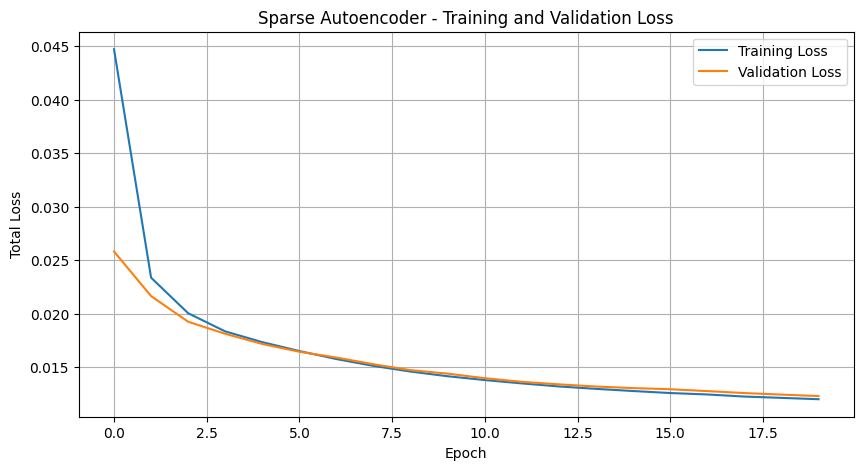

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_sparse["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_sparse["val_loss"],
    label="Validation Loss"
)

plt.title("Sparse Autoencoder - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/sparse_ae_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

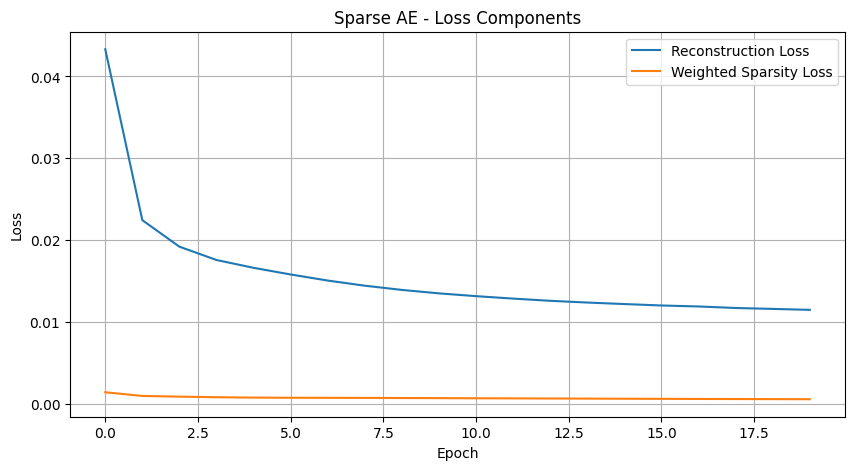

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_sparse["reconstruction_loss"],
    label="Reconstruction Loss"
)

plt.plot(
    [
        LAMBDA_SPARSITY * nilai
        for nilai in history_sparse["sparsity_loss"]
    ],
    label="Weighted Sparsity Loss"
)

plt.title("Sparse AE - Loss Components")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/sparse_ae_loss_components.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

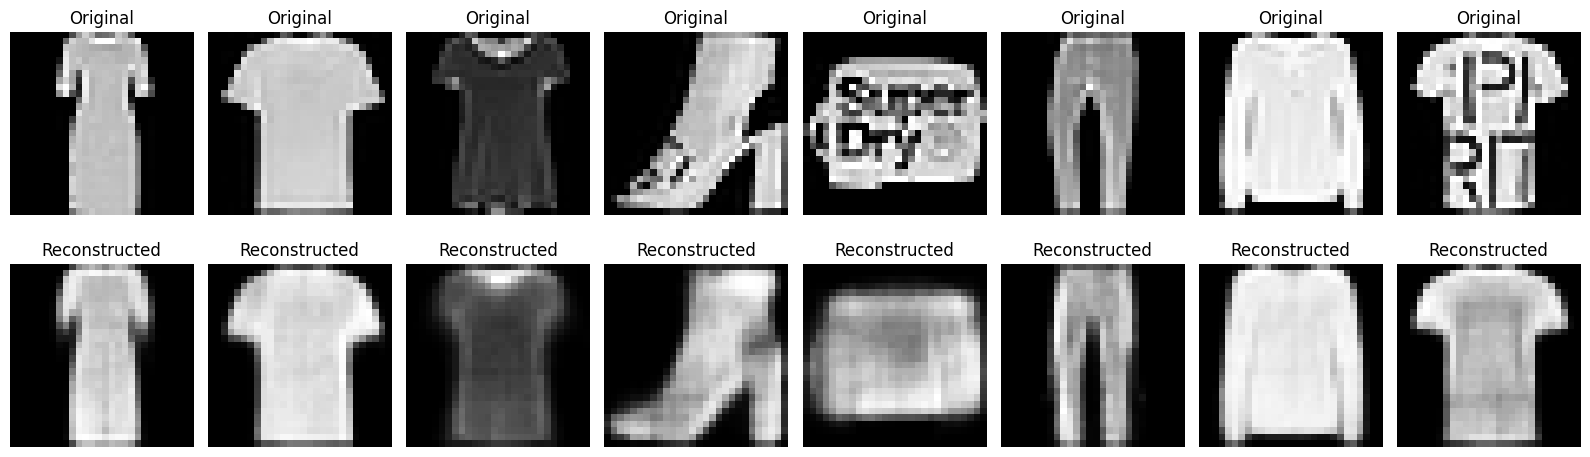

Latent representation shape: torch.Size([8, 64])


In [ ]:
import matplotlib.pyplot as plt

  #load model terbaik
model_sparse.load_state_dict(
    torch.load(checkpoint_sparse, map_location=device)
)

model_sparse.eval()

#ambil 8 gambar dari test set
images, labels = next(iter(test_loader))

images = images[:8].to(device)

with torch.no_grad():
    reconstructed, z = model_sparse(images)

#pindahin ke CPU untuk visualisasinnya
images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    # Gambar asli
    axes[0, i].imshow(
        images[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    #hasil rekonstruksi nya
    axes[1, i].imshow(
        reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/sparse_ae_reconstruction.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Latent representation shape:", z.shape)

In [ ]:
model_sparse.eval()

jumlah_nol = 0
total_aktivasi = 0
total_elemen = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        reconstructed, z = model_sparse(images)
        jumlah_nol += (z <= 1e-6).sum().item()
        total_elemen += z.numel()
        total_aktivasi += z.abs().sum().item()


# persentase aktivasi nol
persentase_nol = (
    jumlah_nol / total_elemen
) * 100

# rata-rata aktivasi
rata_aktivasi = total_aktivasi / total_elemen


print(f"Persentase aktivasi nol : {persentase_nol:.2f}%")
print(f"Rata-rata aktivasi      : {rata_aktivasi:.6f}")

Persentase aktivasi nol : 70.90%
Rata-rata aktivasi      : 0.082225


# Variational Autoencoder

In [ ]:
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/vae.py

import torch
import torch.nn as nn

class VariationalAutoencoder(nn.Module):

    def __init__(self, latent_dim=64):
        super(VariationalAutoencoder, self).__init__()
        #encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        # mean dan log variance
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        #decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        z = mu + epsilon * std
        return z

    def forward(self, x):
        features = self.encoder(x)
        mu = self.fc_mu(features)
        logvar = self.fc_logvar(features)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)
        reconstructed = reconstructed.view(-1, 1, 28, 28)

        return reconstructed, mu, logvar, z

Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/vae.py


In [ ]:
from src.models.vae import VariationalAutoencoder

LATENT_DIM = 64
EPOCHS = 20
LEARNING_RATE = 0.001

model_vae = VariationalAutoencoder(
    latent_dim=LATENT_DIM
).to(device)

optimizer_vae = optim.Adam(
    model_vae.parameters(),
    lr=LEARNING_RATE
)

checkpoint_vae = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "vae.pth"
)

history_vae = {
    "train_loss": [],
    "val_loss": [],
    "reconstruction_loss": [],
    "kl_loss": [],
    "epoch_time": []
}

best_val_loss_vae = float("inf")

print("VAE berhasil dibuat!")
print("Device:", device)

VAE berhasil dibuat!
Device: cuda


In [ ]:
def vae_loss_function(reconstructed, images, mu, logvar):

    # Reconstruction loss
    reconstruction_loss = nn.functional.binary_cross_entropy(
        reconstructed,
        images,
        reduction="sum"
    )

    # KL Divergence
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss

In [ ]:
for epoch in range(EPOCHS):

    start_time = time.time()

    #training
    model_vae.train()
    total_train_loss = 0
    total_reconstruction_loss = 0
    total_kl_loss = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        images = images.to(device)
        #forward pass
        reconstructed, mu, logvar, z = model_vae(images)

        #VAE loss
        loss, reconstruction_loss, kl_loss = vae_loss_function(
            reconstructed,
            images,
            mu,
            logvar
        )

        #backpropagation
        optimizer_vae.zero_grad()
        loss.backward()
        optimizer_vae.step()

        jumlah_data = images.size(0)

        total_train_loss += loss.item()
        total_reconstruction_loss += reconstruction_loss.item()
        total_kl_loss += kl_loss.item()

    # Rata-rata loss per gambar
    train_loss = total_train_loss / len(train_loader.dataset)
    reconstruction_train = (
        total_reconstruction_loss / len(train_loader.dataset)
    )
    kl_train = (
        total_kl_loss / len(train_loader.dataset)
    )

    #validation

    model_vae.eval()

    total_val_loss = 0
    total_val_reconstruction = 0
    total_val_kl = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            reconstructed, mu, logvar, z = model_vae(images)
            loss, reconstruction_loss, kl_loss = vae_loss_function(
                reconstructed,
                images,
                mu,
                logvar
            )
            total_val_loss += loss.item()
            total_val_reconstruction += reconstruction_loss.item()
            total_val_kl += kl_loss.item()

    val_loss = total_val_loss / len(val_loader.dataset)
    reconstruction_val = (
        total_val_reconstruction / len(val_loader.dataset)
    )

    kl_val = (
        total_val_kl / len(val_loader.dataset)
    )

    #save hhistory
    epoch_time = time.time() - start_time

    history_vae["train_loss"].append(train_loss)
    history_vae["val_loss"].append(val_loss)
    history_vae["reconstruction_loss"].append(reconstruction_train)
    history_vae["kl_loss"].append(kl_train)
    history_vae["epoch_time"].append(epoch_time)

    #simpan model terbaik
    if val_loss < best_val_loss_vae:

        best_val_loss_vae = val_loss

        torch.save(
            model_vae.state_dict(),
            checkpoint_vae
        )

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss          : {train_loss:.4f}")
    print(f"Validation Loss     : {val_loss:.4f}")
    print(f"Reconstruction Loss : {reconstruction_train:.4f}")
    print(f"KL Loss             : {kl_train:.4f}")
    print(f"Epoch Time          : {epoch_time:.2f} seconds")

Epoch 1/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    Exception ignored in: if w.is_alive():
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
AssertionError:     can only test a child processself._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch [1/20]
Train Loss          : 308.3926
Validation Loss     : 276.4413
Reconstruction Loss : 297.5185
KL Loss             : 10.8741
Epoch Time          : 9.71 seconds


Epoch 2/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Traceback (most recent call last):

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
self._shutdown_workers()    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a


Epoch [2/20]
Train Loss          : 265.8905
Validation Loss     : 260.7676
Reconstruction Loss : 253.9140
KL Loss             : 11.9765
Epoch Time          : 9.26 seconds


... (50 outputs left out)


Epoch [19/20]
Train Loss          : 240.4960
Validation Loss     : 241.7648
Reconstruction Loss : 228.6673
KL Loss             : 11.8287
Epoch Time          : 10.19 seconds


Epoch 20/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a


Epoch [20/20]
Train Loss          : 240.3607
Validation Loss     : 242.0035
Reconstruction Loss : 228.4856
KL Loss             : 11.8751
Epoch Time          : 9.68 seconds


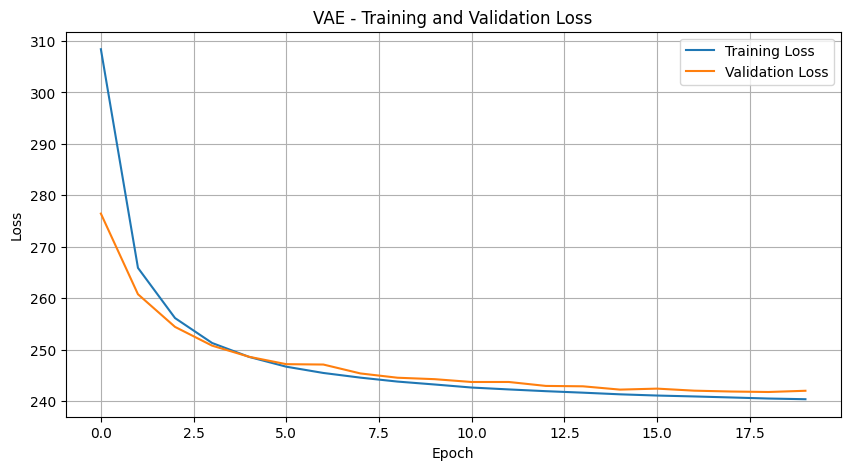

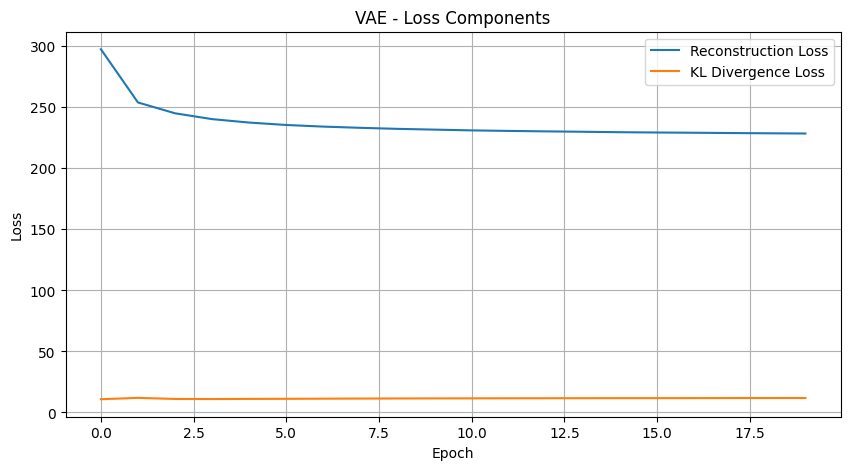

In [ ]:
import matplotlib.pyplot as plt

#grafik total loss
plt.figure(figsize=(10, 5))

plt.plot(history_vae["train_loss"], label="Training Loss")
plt.plot(history_vae["val_loss"], label="Validation Loss")

plt.title("VAE - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vae_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# grafik komponen loss
plt.figure(figsize=(10, 5))

plt.plot(
    history_vae["reconstruction_loss"],
    label="Reconstruction Loss"
)

plt.plot(
    history_vae["kl_loss"],
    label="KL Divergence Loss"
)

plt.title("VAE - Loss Components")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vae_loss_components.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

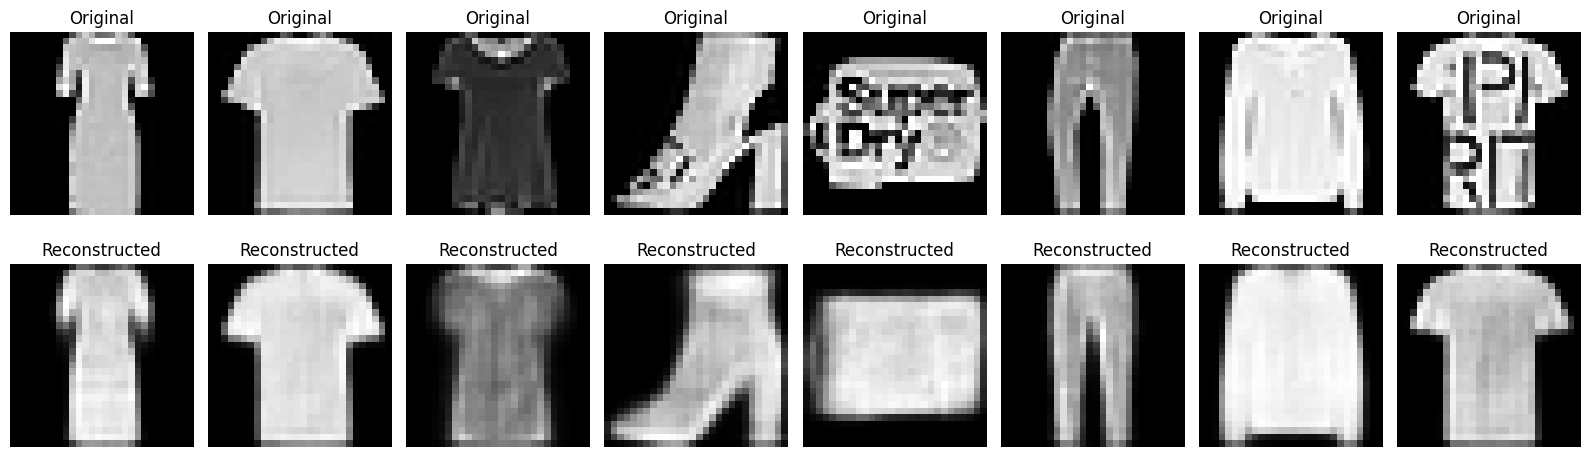

Mean shape: torch.Size([8, 64])
Log variance shape: torch.Size([8, 64])
Latent shape: torch.Size([8, 64])


In [ ]:
#load model terbaik
model_vae.load_state_dict(
    torch.load(checkpoint_vae, map_location=device)
)
model_vae.eval()

#ambil 8 gambar test
images, labels = next(iter(test_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstructed, mu, logvar, z = model_vae(images)
images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    axes[0, i].imshow(
        images[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    axes[1, i].imshow(
        reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vae_reconstruction.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean shape:", mu.shape)
print("Log variance shape:", logvar.shape)
print("Latent shape:", z.shape)

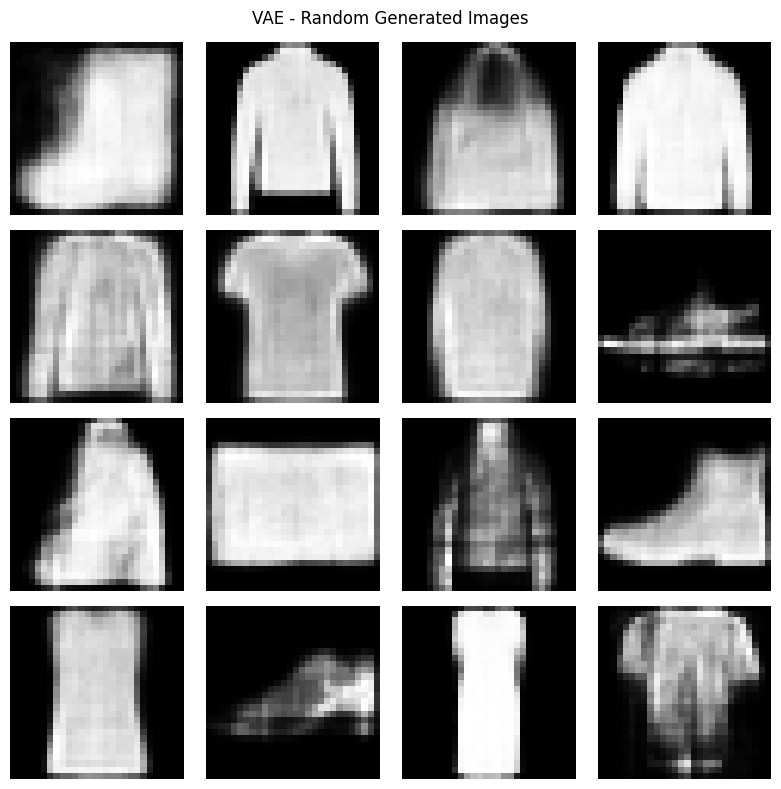

In [ ]:
model_vae.eval()

# 16 latent vectors dari distribusi normal standar
with torch.no_grad():

    random_z = torch.randn(
        16,
        LATENT_DIM
    ).to(device)
    generated_images = model_vae.decoder(random_z)

    generated_images = generated_images.view(
        -1, 1, 28, 28
    )

generated_images = generated_images.cpu()

#menampilkan visualisasi hasil generasi
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle("VAE - Random Generated Images")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vae_generated_images.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Generative Adversarial Network (GAN)

In [6]:
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/vanilla_gan.py

import torch
import torch.nn as nn


#Generator =
class Generator(nn.Module):

    def __init__(self, noise_dim=100):
        super(Generator, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        generated = self.network(z)
        generated = generated.view(-1, 1, 28, 28)
        return generated


#Discriminator =
class Discriminator(nn.Module):

    def __init__(self):
        super(Discriminator, self).__init__()

        self.network = nn.Sequential(

            nn.Flatten(),
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        output = self.network(x)
        return output

Overwriting /content/drive/MyDrive/DeepLearning_TakeHome/src/models/vanilla_gan.py


In [4]:
import sys
from torch.utils.data import Dataset, DataLoader

sys.path.insert(0, PROJECT_PATH)


class SkalaMinSatuKePlusSatu(Dataset):
    def __init__(self, dataset_dasar):
        self.dataset_dasar = dataset_dasar

    def __len__(self):
        return len(self.dataset_dasar)

    def __getitem__(self, idx):
        gambar, label = self.dataset_dasar[idx]
        return gambar * 2.0 - 1.0, label


train_gan = SkalaMinSatuKePlusSatu(train_set)
val_gan = SkalaMinSatuKePlusSatu(val_set)
test_gan = SkalaMinSatuKePlusSatu(test_set)

train_loader_gan = DataLoader(
    train_gan, batch_size=BATCH_SIZE, shuffle=True, num_workers=2
)
val_loader_gan = DataLoader(
    val_gan, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)
test_loader_gan = DataLoader(
    test_gan, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)

# pengecekan: jumlah data harus sama persis dengan AE/VAE
assert len(train_gan) == len(train_set)
assert len(val_gan) == len(val_set)
assert len(test_gan) == len(test_set)

gambar_cek, _ = next(iter(train_loader_gan))

print("Dataset GAN berhasil disiapkan (split sama dengan AE/VAE)!")
print("Train:", len(train_gan))
print("Validation:", len(val_gan))
print("Test:", len(test_gan))
print("Rentang piksel:", round(gambar_cek.min().item(), 2), "sampai", round(gambar_cek.max().item(), 2))

Dataset GAN berhasil disiapkan (split sama dengan AE/VAE)!
Train: 56000
Validation: 7000
Test: 7000
Rentang piksel: -1.0 sampai 1.0


In [7]:
from src.models.vanilla_gan import Generator, Discriminator

NOISE_DIM = 100
EPOCHS_GAN = 50
LEARNING_RATE_GAN = 0.0002

#Generator
generator = Generator(
    noise_dim=NOISE_DIM
).to(device)

#Discriminator
discriminator = Discriminator().to(device)

#optimizer masing-masing jaringan
optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE_GAN,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE_GAN,
    betas=(0.5, 0.999)
)

#loss function
criterion_gan = nn.BCELoss()

#checkpoint
checkpoint_G = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "vanilla_gan_generator.pth"
)

checkpoint_D = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "vanilla_gan_discriminator.pth"
)

#riwayat trainingnya
history_gan = {
    "generator_loss": [],
    "discriminator_loss": [],
    "epoch_time": []
}

print("Generator dan Discriminator berhasil dibuat!")
print("Device:", device)

NameError: name 'optim' is not defined

Epoch 1/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [1/50]
Generator Loss     : 1.8256
Discriminator Loss : 0.3351
Epoch Time         : 12.50 seconds


Epoch 2/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [2/50]
Generator Loss     : 2.6302
Discriminator Loss : 0.3167
Epoch Time         : 10.90 seconds


Epoch 3/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [3/50]
Generator Loss     : 2.5985
Discriminator Loss : 0.3342
Epoch Time         : 10.94 seconds


... (10 outputs left out)

Epoch 9/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [9/50]
Generator Loss     : 1.7826
Discriminator Loss : 0.4470
Epoch Time         : 11.30 seconds


Epoch 10/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [10/50]
Generator Loss     : 1.7908
Discriminator Loss : 0.4417
Epoch Time         : 12.22 seconds


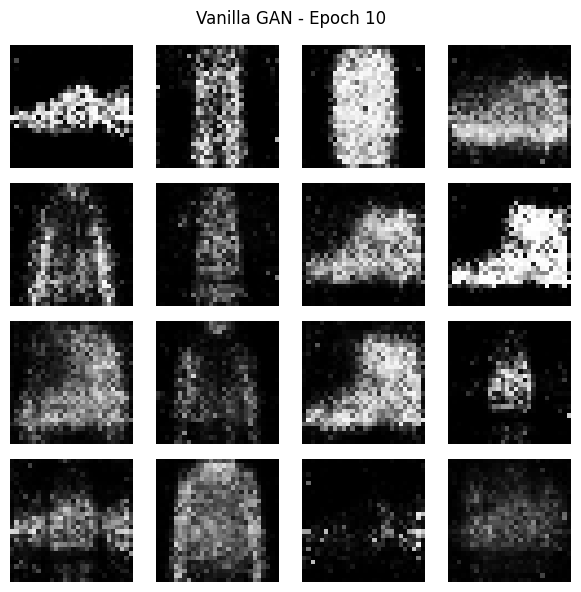

Epoch 11/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [11/50]
Generator Loss     : 1.7191
Discriminator Loss : 0.4643
Epoch Time         : 11.85 seconds


Epoch 12/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [12/50]
Generator Loss     : 1.6871
Discriminator Loss : 0.4725
Epoch Time         : 11.88 seconds


Epoch 13/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [13/50]
Generator Loss     : 1.6255
Discriminator Loss : 0.4833
Epoch Time         : 11.55 seconds


... (10 outputs left out)

Epoch 19/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [19/50]
Generator Loss     : 1.4632
Discriminator Loss : 0.4997
Epoch Time         : 11.44 seconds


Epoch 20/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [20/50]
Generator Loss     : 1.4607
Discriminator Loss : 0.4939
Epoch Time         : 11.64 seconds


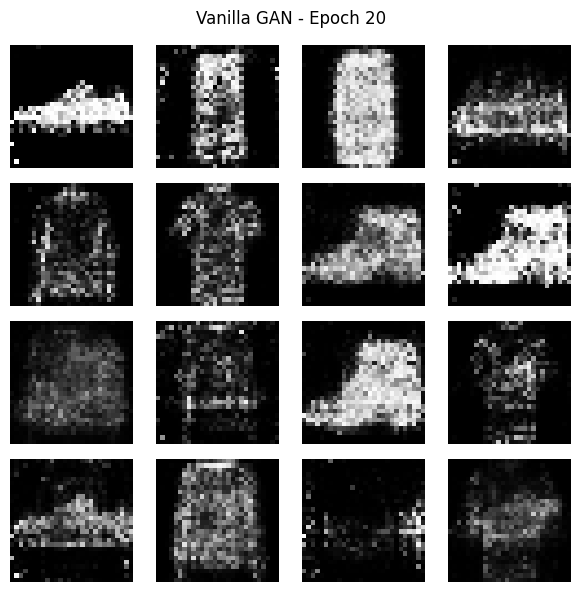

Epoch 21/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [21/50]
Generator Loss     : 1.4782
Discriminator Loss : 0.4968
Epoch Time         : 12.13 seconds


Epoch 22/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [22/50]
Generator Loss     : 1.4700
Discriminator Loss : 0.4985
Epoch Time         : 12.25 seconds


Epoch 23/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [23/50]
Generator Loss     : 1.4454
Discriminator Loss : 0.4994
Epoch Time         : 12.59 seconds


... (10 outputs left out)

Epoch 29/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [29/50]
Generator Loss     : 1.3642
Discriminator Loss : 0.5084
Epoch Time         : 12.30 seconds


Epoch 30/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [30/50]
Generator Loss     : 1.3758
Discriminator Loss : 0.5117
Epoch Time         : 12.26 seconds


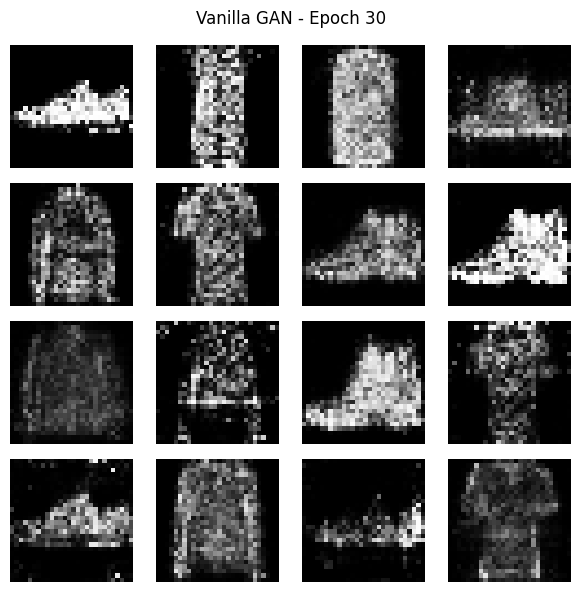

Epoch 31/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [31/50]
Generator Loss     : 1.3903
Discriminator Loss : 0.5063
Epoch Time         : 11.65 seconds


Epoch 32/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [32/50]
Generator Loss     : 1.3692
Discriminator Loss : 0.5146
Epoch Time         : 11.35 seconds


Epoch 33/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [33/50]
Generator Loss     : 1.3486
Discriminator Loss : 0.5150
Epoch Time         : 12.53 seconds


... (10 outputs left out)

Epoch 39/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [39/50]
Generator Loss     : 1.3301
Discriminator Loss : 0.5203
Epoch Time         : 11.45 seconds


Epoch 40/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [40/50]
Generator Loss     : 1.3329
Discriminator Loss : 0.5187
Epoch Time         : 12.13 seconds


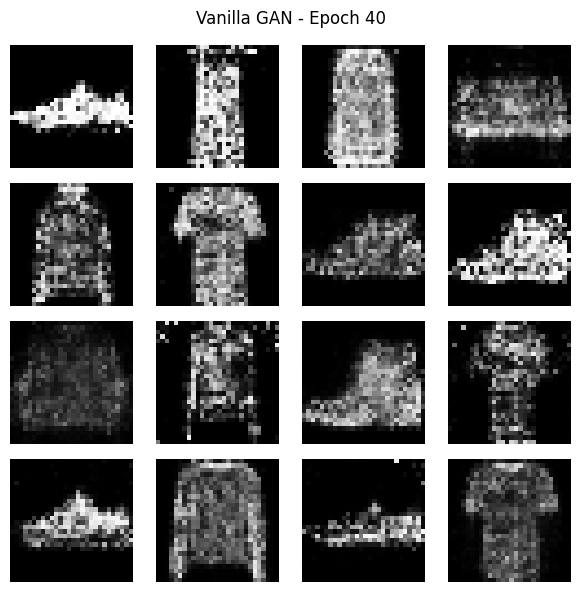

Epoch 41/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [41/50]
Generator Loss     : 1.3207
Discriminator Loss : 0.5175
Epoch Time         : 12.30 seconds


Epoch 42/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [42/50]
Generator Loss     : 1.3063
Discriminator Loss : 0.5222
Epoch Time         : 12.21 seconds


Epoch 43/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [43/50]
Generator Loss     : 1.3216
Discriminator Loss : 0.5181
Epoch Time         : 12.50 seconds


... (10 outputs left out)

Epoch 49/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [49/50]
Generator Loss     : 1.3144
Discriminator Loss : 0.5162
Epoch Time         : 12.08 seconds


Epoch 50/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [50/50]
Generator Loss     : 1.3250
Discriminator Loss : 0.5173
Epoch Time         : 12.21 seconds


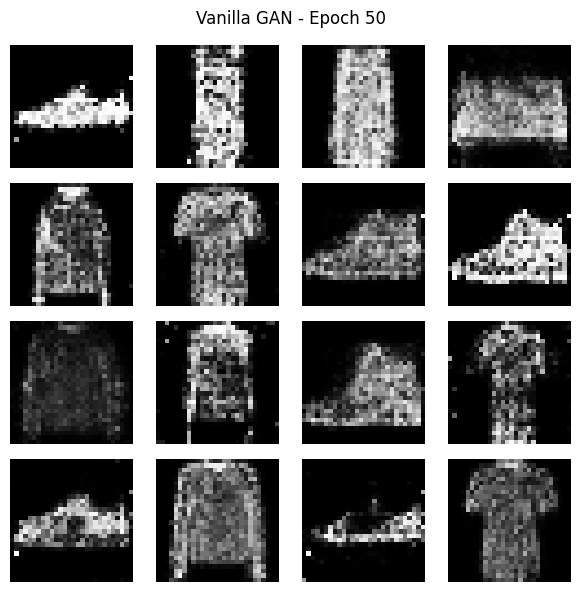


Training Vanilla GAN selesai!


In [ ]:
#Fixed noise untuk melihat perkembangan gambar
#menggunakan input random yang sama setiap epoch
fixed_noise = torch.randn(
    16,
    NOISE_DIM
).to(device)


for epoch in range(EPOCHS_GAN):
    start_time = time.time()
    generator.train()
    discriminator.train()
    total_loss_G = 0
    total_loss_D = 0

    for images, labels in tqdm(
        train_loader_gan,
        desc=f"Epoch {epoch+1}/{EPOCHS_GAN}"
    ):
        images = images.to(device)
        batch_size = images.size(0)
        # Label untuk gambar asli dan palsu
        real_labels = torch.ones(
            batch_size, 1
        ).to(device)

        fake_labels = torch.zeros(
            batch_size, 1
        ).to(device)

        #1. train discriminator =
        optimizer_D.zero_grad()
        output_real = discriminator(images) #mempelajari gambar asli

        loss_real = criterion_gan(
            output_real,
            real_labels
        )

        #generator membuat gambar palsu
        noise = torch.randn(
            batch_size,
            NOISE_DIM
        ).to(device)

        fake_images = generator(noise)

        #discriminator mempelajari gambar palsu
        output_fake = discriminator(
            fake_images.detach()
        )
        loss_fake = criterion_gan(
            output_fake,
            fake_labels
        )

        #total Discriminator loss
        loss_D = (loss_real + loss_fake) / 2

        loss_D.backward()
        optimizer_D.step()

        #2. train generator =
        optimizer_G.zero_grad()
        #ini membuat gambar palsu baru
        noise = torch.randn(
            batch_size,
            NOISE_DIM
        ).to(device)

        fake_images = generator(noise)

        #generator ingin Discriminator
        # menganggap gambar palsu sebagai real
        output_fake = discriminator(fake_images)

        loss_G = criterion_gan(
            output_fake,
            real_labels
        )

        loss_G.backward()
        optimizer_G.step()

        #nilai loss disimpan
        total_loss_D += loss_D.item()
        total_loss_G += loss_G.item()

    avg_loss_D = total_loss_D / len(train_loader_gan)
    avg_loss_G = total_loss_G / len(train_loader_gan)

    epoch_time = time.time() - start_time

    history_gan["discriminator_loss"].append(avg_loss_D)
    history_gan["generator_loss"].append(avg_loss_G)
    history_gan["epoch_time"].append(epoch_time)

    #checkpoint setiap 10 epoch
    if (epoch + 1) % 10 == 0:

        torch.save(
            generator.state_dict(),
            checkpoint_G
        )

        torch.save(
            discriminator.state_dict(),
            checkpoint_D
        )

    print(f"\nEpoch [{epoch+1}/{EPOCHS_GAN}]")
    print(f"Generator Loss     : {avg_loss_G:.4f}")
    print(f"Discriminator Loss : {avg_loss_D:.4f}")
    print(f"Epoch Time         : {epoch_time:.2f} seconds")

    #3. lihat hasil generator =

    if (epoch + 1) % 10 == 0:
        generator.eval()
        with torch.no_grad():
            generated = generator(fixed_noise)
            # Normalisasi dari [-1, 1] menjadi [0, 1]
            generated = (generated + 1) / 2
        fig, axes = plt.subplots(4, 4, figsize=(6, 6))
        for i, ax in enumerate(axes.flat):
            ax.imshow(
                generated[i].cpu().squeeze(),
                cmap="gray",
                vmin=0,
                vmax=1
            )
            ax.axis("off")

        plt.suptitle(f"Vanilla GAN - Epoch {epoch+1}")
        plt.tight_layout()
        plt.show()

        generator.train()


# Simpan checkpoint akhir juga
torch.save(generator.state_dict(), checkpoint_G)
torch.save(discriminator.state_dict(), checkpoint_D)

print("\nTraining Vanilla GAN selesai!")

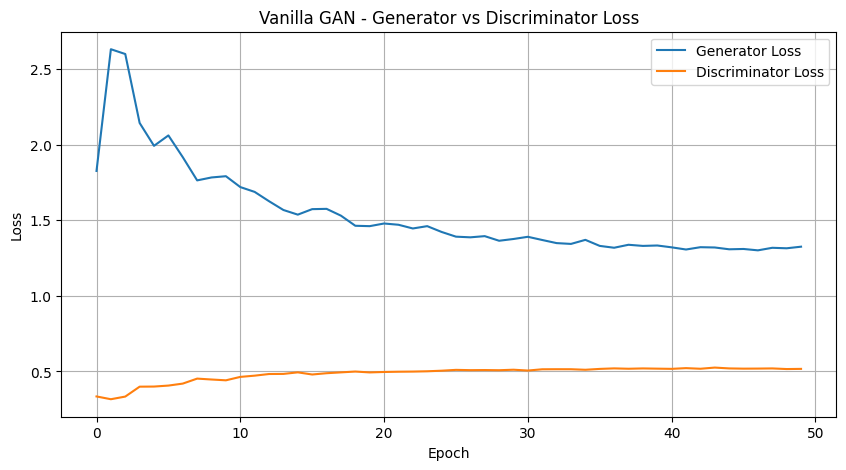

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gan["generator_loss"],
    label="Generator Loss"
)

plt.plot(
    history_gan["discriminator_loss"],
    label="Discriminator Loss"
)

plt.title("Vanilla GAN - Generator vs Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vanilla_gan_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

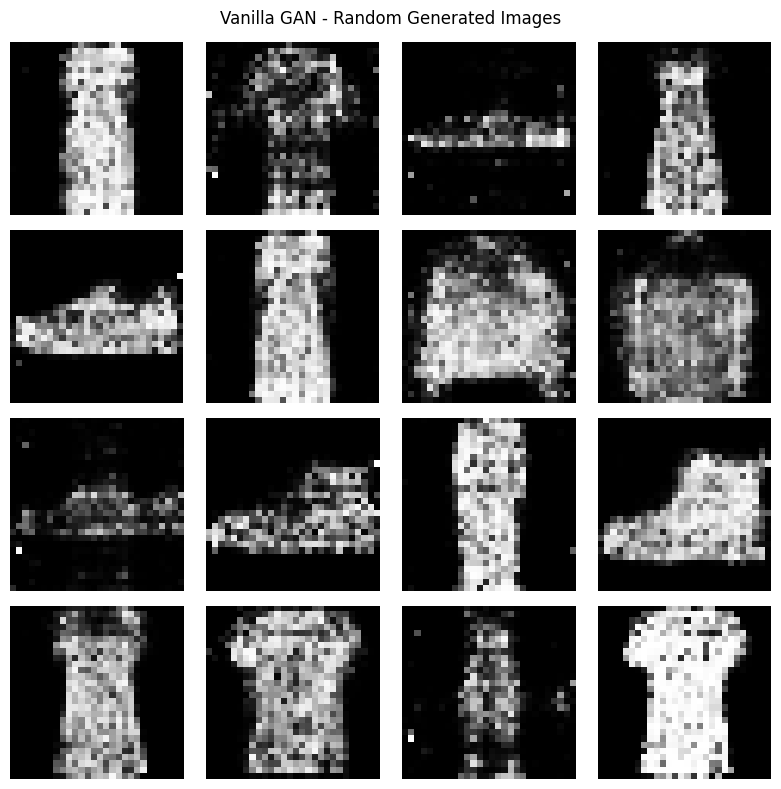

In [ ]:
generator.eval()

with torch.no_grad():
    random_noise = torch.randn(
        16,
        NOISE_DIM
    ).to(device)
    generated_images = generator(random_noise)
    generated_images = (generated_images + 1) / 2

generated_images = generated_images.cpu()

# Visualisasi
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

plt.suptitle("Vanilla GAN - Random Generated Images")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/vanilla_gan_generated.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# DCGAN (Deep Convolutional GAN)

In [ ]:
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/dcgan.py

import torch
import torch.nn as nn


#Generator
class DCGANGenerator(nn.Module):

    def __init__(self, noise_dim=100):
        super(DCGANGenerator, self).__init__()

        self.network = nn.Sequential(

            # 1 x 1 -> 7 x 7
            nn.ConvTranspose2d(
                noise_dim, 128,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 7 x 7 -> 14 x 14
            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 14 x 14 -> 28 x 28
            nn.ConvTranspose2d(
                64, 1,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)


# Discriminator
class DCGANDiscriminator(nn.Module):

    def __init__(self):
        super(DCGANDiscriminator, self).__init__()

        self.network = nn.Sequential(

            # 28 x 28 -> 14 x 14
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # 14 x 14 -> 7 x 7
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 7 x 7 -> 1 x 1
            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x).view(-1, 1)

Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/dcgan.py


In [ ]:
from src.models.dcgan import DCGANGenerator, DCGANDiscriminator

NOISE_DIM = 100
EPOCHS_DCGAN = 50
LEARNING_RATE_DCGAN = 0.0002

#model
generator_dcgan = DCGANGenerator(
    noise_dim=NOISE_DIM
).to(device)

discriminator_dcgan = DCGANDiscriminator().to(device)


# Inisialisasi bobot DCGAN
def weights_init(model):

    nama_layer = model.__class__.__name__

    if "Conv" in nama_layer:

        nn.init.normal_(
            model.weight.data,
            0.0,
            0.02
        )

    elif "BatchNorm" in nama_layer:

        nn.init.normal_(
            model.weight.data,
            1.0,
            0.02
        )

        nn.init.constant_(
            model.bias.data,
            0
        )


generator_dcgan.apply(weights_init)
discriminator_dcgan.apply(weights_init)


#optimizer
optimizer_G_dcgan = optim.Adam(
    generator_dcgan.parameters(),
    lr=LEARNING_RATE_DCGAN,
    betas=(0.5, 0.999)
)

optimizer_D_dcgan = optim.Adam(
    discriminator_dcgan.parameters(),
    lr=LEARNING_RATE_DCGAN,
    betas=(0.5, 0.999)
)

criterion_dcgan = nn.BCELoss()


#checkpoint
checkpoint_G_dcgan = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "dcgan_generator.pth"
)

checkpoint_D_dcgan = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "dcgan_discriminator.pth"
)


history_dcgan = {
    "generator_loss": [],
    "discriminator_loss": [],
    "epoch_time": []
}

print("DCGAN berhasil dibuat!")
print("Device:", device)

DCGAN berhasil dibuat!
Device: cuda


In [ ]:
noise_test = torch.randn(
    4,
    NOISE_DIM,
    1,
    1
).to(device)

with torch.no_grad():

    gambar_test = generator_dcgan(noise_test)

    hasil_discriminator = discriminator_dcgan(
        gambar_test
    )

print("Generator output:", gambar_test.shape)
print("Discriminator output:", hasil_discriminator.shape)

Generator output: torch.Size([4, 1, 28, 28])
Discriminator output: torch.Size([4, 1])


Epoch 1/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [1/50]
Generator Loss     : 2.0993
Discriminator Loss : 0.2249
Epoch Time         : 16.99 seconds


Epoch 2/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [2/50]
Generator Loss     : 2.2483
Discriminator Loss : 0.2035
Epoch Time         : 16.52 seconds


Epoch 3/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [3/50]
Generator Loss     : 1.9550
Discriminator Loss : 0.2714
Epoch Time         : 16.71 seconds


... (10 outputs left out)

Epoch 9/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [9/50]
Generator Loss     : 1.3664
Discriminator Loss : 0.4444
Epoch Time         : 16.45 seconds


Epoch 10/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [10/50]
Generator Loss     : 1.3386
Discriminator Loss : 0.4597
Epoch Time         : 16.07 seconds


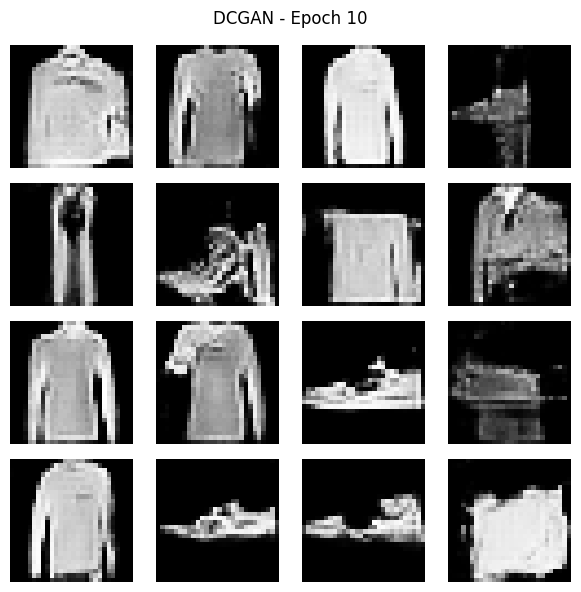

Epoch 11/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [11/50]
Generator Loss     : 1.3188
Discriminator Loss : 0.4769
Epoch Time         : 16.39 seconds


Epoch 12/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [12/50]
Generator Loss     : 1.2875
Discriminator Loss : 0.4784
Epoch Time         : 17.08 seconds


Epoch 13/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [13/50]
Generator Loss     : 1.2845
Discriminator Loss : 0.4884
Epoch Time         : 17.27 seconds


... (10 outputs left out)

Epoch 19/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [19/50]
Generator Loss     : 1.2617
Discriminator Loss : 0.5104
Epoch Time         : 16.94 seconds


Epoch 20/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [20/50]
Generator Loss     : 1.2502
Discriminator Loss : 0.5038
Epoch Time         : 16.44 seconds


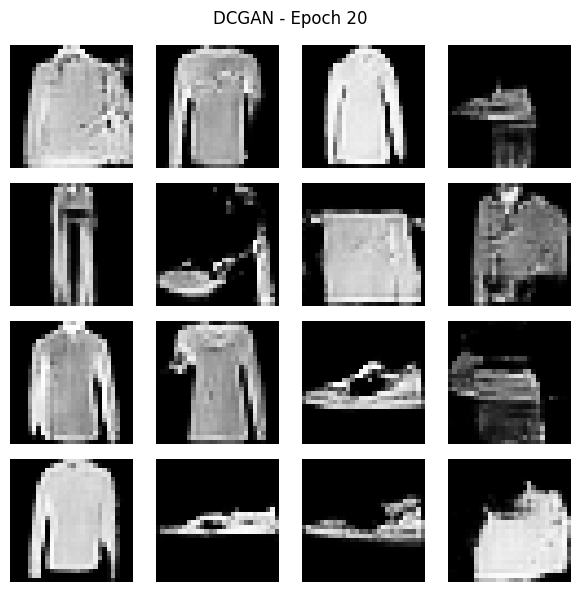

Epoch 21/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [21/50]
Generator Loss     : 1.2515
Discriminator Loss : 0.5076
Epoch Time         : 17.04 seconds


Epoch 22/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [22/50]
Generator Loss     : 1.2500
Discriminator Loss : 0.5017
Epoch Time         : 17.11 seconds


Epoch 23/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [23/50]
Generator Loss     : 1.2498
Discriminator Loss : 0.5205
Epoch Time         : 17.48 seconds


... (10 outputs left out)

Epoch 29/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [29/50]
Generator Loss     : 1.2700
Discriminator Loss : 0.5334
Epoch Time         : 16.75 seconds


Epoch 30/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [30/50]
Generator Loss     : 1.2544
Discriminator Loss : 0.4914
Epoch Time         : 16.91 seconds


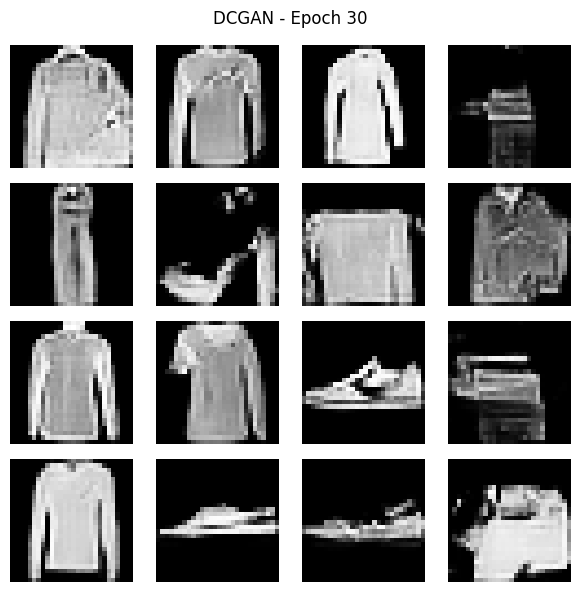

Epoch 31/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [31/50]
Generator Loss     : 1.2744
Discriminator Loss : 0.4986
Epoch Time         : 16.85 seconds


Epoch 32/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [32/50]
Generator Loss     : 1.2866
Discriminator Loss : 0.5075
Epoch Time         : 17.05 seconds


Epoch 33/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [33/50]
Generator Loss     : 1.2841
Discriminator Loss : 0.5086
Epoch Time         : 17.65 seconds


... (10 outputs left out)

Epoch 39/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [39/50]
Generator Loss     : 1.3180
Discriminator Loss : 0.4956
Epoch Time         : 16.91 seconds


Epoch 40/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [40/50]
Generator Loss     : 1.3084
Discriminator Loss : 0.4884
Epoch Time         : 17.14 seconds


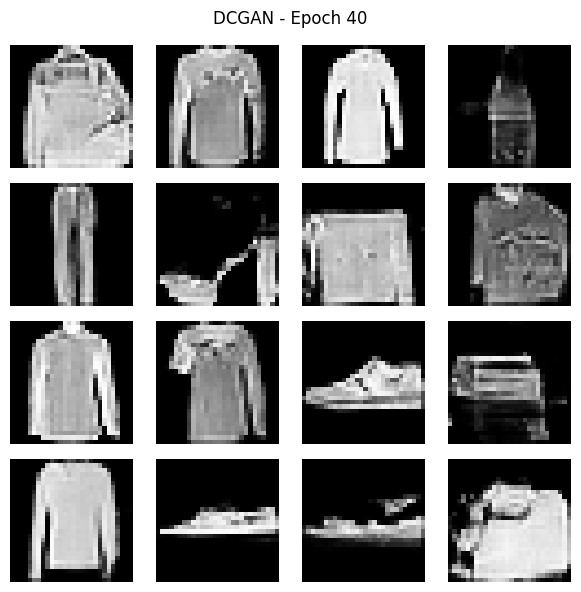

Epoch 41/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [41/50]
Generator Loss     : 1.3277
Discriminator Loss : 0.4864
Epoch Time         : 17.20 seconds


Epoch 42/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [42/50]
Generator Loss     : 1.3215
Discriminator Loss : 0.4847
Epoch Time         : 17.72 seconds


Epoch 43/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [43/50]
Generator Loss     : 1.3306
Discriminator Loss : 0.5116
Epoch Time         : 17.36 seconds


... (10 outputs left out)

Epoch 49/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [49/50]
Generator Loss     : 1.3510
Discriminator Loss : 0.4928
Epoch Time         : 17.36 seconds


Epoch 50/50:   0%|          | 0/375 [00:00<?, ?it/s]


Epoch [50/50]
Generator Loss     : 1.3658
Discriminator Loss : 0.4690
Epoch Time         : 17.21 seconds


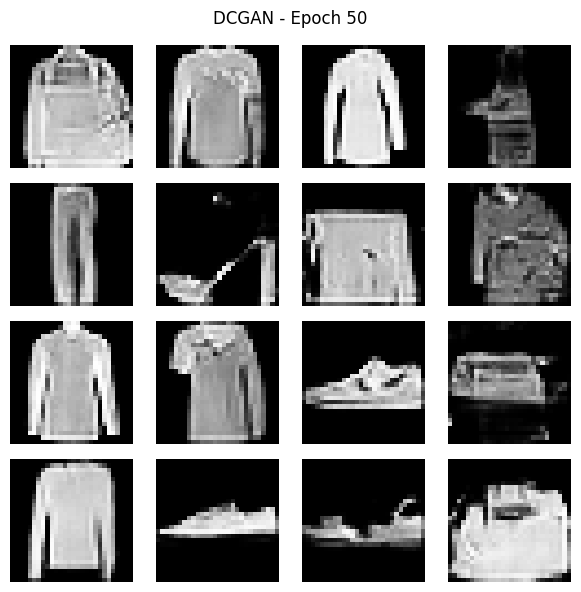


Training DCGAN selesai!


In [ ]:
fixed_noise_dcgan = torch.randn(
    16,
    NOISE_DIM,
    1,
    1
).to(device)


for epoch in range(EPOCHS_DCGAN):
    start_time = time.time()
    generator_dcgan.train()
    discriminator_dcgan.train()
    total_loss_G = 0
    total_loss_D = 0

    for images, labels in tqdm(
        train_loader_gan,
        desc=f"Epoch {epoch+1}/{EPOCHS_DCGAN}"
    ):

        images = images.to(device)
        batch_size = images.size(0)
        real_labels = torch.ones(
            batch_size, 1
        ).to(device)
        fake_labels = torch.zeros(
            batch_size, 1
        ).to(device)


        #train discriminator ==>
        optimizer_D_dcgan.zero_grad()
        output_real = discriminator_dcgan(images)
        loss_real = criterion_dcgan(
            output_real,
            real_labels
        )

        noise = torch.randn(
            batch_size,
            NOISE_DIM,
            1,
            1
        ).to(device)

        fake_images = generator_dcgan(noise)

        output_fake = discriminator_dcgan(
            fake_images.detach()
        )

        loss_fake = criterion_dcgan(
            output_fake,
            fake_labels
        )

        loss_D = (loss_real + loss_fake) / 2

        loss_D.backward()
        optimizer_D_dcgan.step()


        #train generator ==>
        optimizer_G_dcgan.zero_grad()
        noise = torch.randn(
            batch_size,
            NOISE_DIM,
            1,
            1
        ).to(device)

        fake_images = generator_dcgan(noise)
        output_fake = discriminator_dcgan(fake_images)

        loss_G = criterion_dcgan(
            output_fake,
            real_labels
        )

        loss_G.backward()
        optimizer_G_dcgan.step()


        total_loss_D += loss_D.item()
        total_loss_G += loss_G.item()


    avg_loss_D = total_loss_D / len(train_loader_gan)
    avg_loss_G = total_loss_G / len(train_loader_gan)

    epoch_time = time.time() - start_time

    history_dcgan["discriminator_loss"].append(avg_loss_D)
    history_dcgan["generator_loss"].append(avg_loss_G)
    history_dcgan["epoch_time"].append(epoch_time)


    #save checkpoint tiap 10 epoch
    if (epoch + 1) % 10 == 0:
        torch.save(
            generator_dcgan.state_dict(),
            checkpoint_G_dcgan
        )
        torch.save(
            discriminator_dcgan.state_dict(),
            checkpoint_D_dcgan
        )


    print(f"\nEpoch [{epoch+1}/{EPOCHS_DCGAN}]")
    print(f"Generator Loss     : {avg_loss_G:.4f}")
    print(f"Discriminator Loss : {avg_loss_D:.4f}")
    print(f"Epoch Time         : {epoch_time:.2f} seconds")


    #setiap 10 epoch
    if (epoch + 1) % 10 == 0:
        generator_dcgan.eval()
        with torch.no_grad():
            generated = generator_dcgan(fixed_noise_dcgan)
            generated = (generated + 1) / 2
        fig, axes = plt.subplots(4, 4, figsize=(6, 6))
        for i, ax in enumerate(axes.flat):
            ax.imshow(
                generated[i].cpu().squeeze(),
                cmap="gray",
                vmin=0,
                vmax=1
            )

            ax.axis("off")

        plt.suptitle(f"DCGAN - Epoch {epoch+1}")
        plt.tight_layout()
        plt.show()


#save checkpoint akhir
torch.save(
    generator_dcgan.state_dict(),
    checkpoint_G_dcgan
)

torch.save(
    discriminator_dcgan.state_dict(),
    checkpoint_D_dcgan
)

print("\nTraining DCGAN selesai!")

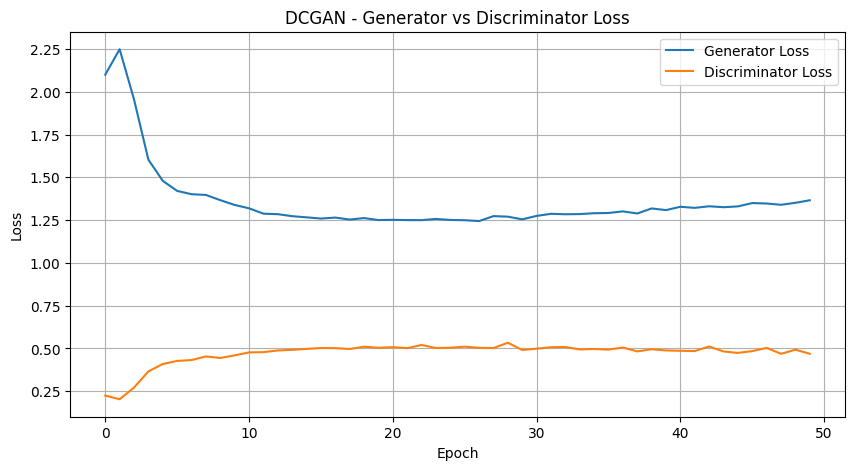

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_dcgan["generator_loss"],
    label="Generator Loss"
)

plt.plot(
    history_dcgan["discriminator_loss"],
    label="Discriminator Loss"
)

plt.title("DCGAN - Generator vs Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/dcgan_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

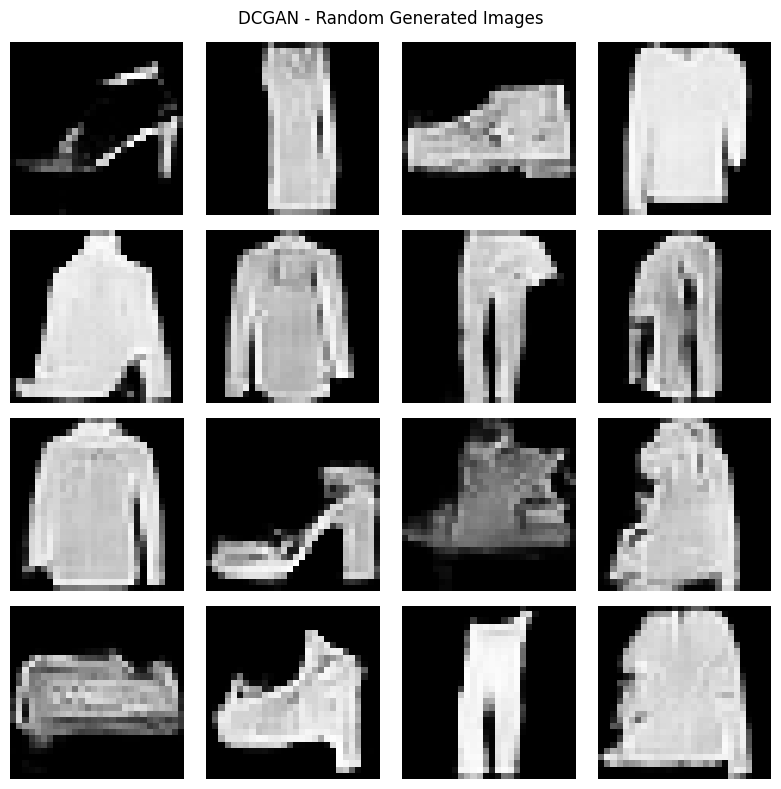

In [ ]:
generator_dcgan.eval()

with torch.no_grad():
    random_noise = torch.randn(
        16,NOISE_DIM,1,1
    ).to(device)
    generated_images = generator_dcgan(random_noise)
    generated_images = (generated_images + 1) / 2
generated_images = generated_images.cpu()
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("DCGAN - Random Generated Images")
plt.tight_layout()
plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results/figures/dcgan_generated.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

DDPM (Denoising Diffusion Probabilistic Model)

In [ ]:
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/ddpm.py

import torch
import torch.nn as nn
import math


class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2

        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(
            torch.arange(half_dim, device=device) * -embeddings
        )
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat(
            (embeddings.sin(), embeddings.cos()), dim=1
        )
        return embeddings


class DDPMModel(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalPositionEmbeddings(time_dim),
            nn.Linear(time_dim, 128),
            nn.ReLU()
        )

        self.time_layer1 = nn.Linear(128, 64)
        self.time_layer2 = nn.Linear(128, 128)

        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1)
        self.conv3 = nn.Conv2d(128, 128, kernel_size=3, padding=1)

        self.up = nn.ConvTranspose2d(
            128, 64, kernel_size=4, stride=2, padding=1
        )

        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.output = nn.Conv2d(64, 1, kernel_size=3, padding=1)

        self.relu = nn.ReLU()

    def forward(self, x, time):
        t = self.time_embedding(time)

        t1 = self.time_layer1(t)[:, :, None, None]
        t2 = self.time_layer2(t)[:, :, None, None]

        x = self.conv1(x)
        x = self.relu(x + t1)

        x = self.conv2(x)
        x = self.relu(x + t2)

        x = self.conv3(x)
        x = self.relu(x)

        x = self.up(x)
        x = self.relu(x)

        x = self.conv4(x)
        x = self.relu(x)

        return self.output(x)


Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/ddpm.py


In [ ]:
#inisialisasi model dulu
from src.models.ddpm import DDPMModel

ddpm_model = DDPMModel().to(device)

print("DDPM berhasil dibuat!")
print("Device:", device)


DDPM berhasil dibuat!
Device: cuda


In [ ]:
#tes arsitektur nya
gambar_test = torch.randn(4, 1, 28, 28).to(device)
waktu_test = torch.randint(0, 200, (4,)).to(device)

with torch.no_grad():
    prediksi_noise = ddpm_model(gambar_test, waktu_test)

print("Input shape:", gambar_test.shape)
print("Output shape:", prediksi_noise.shape)

Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 1, 28, 28])


In [ ]:
T = 200 #jumlah langkah diffusion
beta = torch.linspace(0.0001, 0.02, T).to(device)

#alpha
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

#alpha bar sebelumnya
alpha_bar_prev = torch.cat([
    torch.tensor([1.0]).to(device),
    alpha_bar[:-1]
])

#variance untuk reverse diffusion
posterior_variance = (
    beta * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)
)

print("Noise scheduler berhasil dibuat!")
print("Jumlah timestep:", T)
print("Beta awal:", beta[0].item())
print("Beta akhir:", beta[-1].item())

Noise scheduler berhasil dibuat!
Jumlah timestep: 200
Beta awal: 9.999999747378752e-05
Beta akhir: 0.019999999552965164


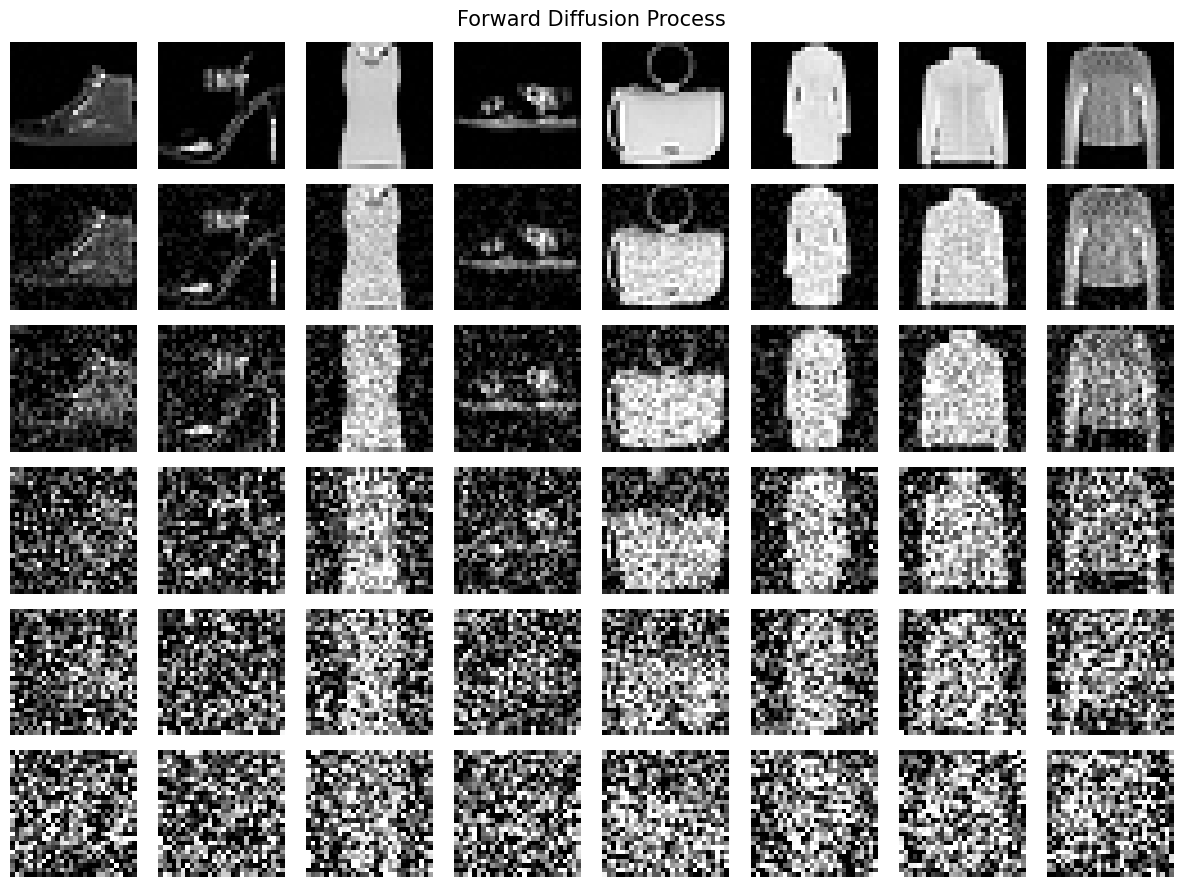

In [ ]:
import matplotlib.pyplot as plt

# Ambil satu batch gambar
gambar_asli, _ = next(iter(train_loader_gan))
gambar_asli = gambar_asli[:8].to(device)

# Pilih beberapa timestep
timesteps = [0, 20, 50, 100, 150, 199]

fig, axes = plt.subplots(6, 8, figsize=(12, 9))

for row, t in enumerate(timesteps):

    waktu = torch.full(
        (gambar_asli.size(0),),
        t,
        device=device,
        dtype=torch.long
    )

    noise = torch.randn_like(gambar_asli)

    alpha_bar_t = alpha_bar[t]

    gambar_noise = (
        torch.sqrt(alpha_bar_t) * gambar_asli
        + torch.sqrt(1 - alpha_bar_t) * noise
    )

    for col in range(8):
        axes[row, col].imshow(
            gambar_noise[col].squeeze().cpu(),
            cmap="gray",
            vmin=-1,
            vmax=1
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"t={t}",
        fontsize=11
    )

plt.suptitle("Forward Diffusion Process", fontsize=15)
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "results", "figures", "ddpm_forward_diffusion.png"),
    dpi=150
)

plt.show()

In [ ]:
import time
from tqdm.auto import tqdm

EPOCHS_DDPM = 20
LEARNING_RATE_DDPM = 0.0002

optimizer_ddpm = optim.Adam(
    ddpm_model.parameters(),
    lr=LEARNING_RATE_DDPM
)

criterion_ddpm = nn.MSELoss()
history_ddpm = {
    "loss": [],
    "epoch_time": []
}

checkpoint_ddpm = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "ddpm.pth"
)

for epoch in range(EPOCHS_DDPM):
    ddpm_model.train()
    total_loss = 0
    jumlah_batch = 0
    waktu_mulai = time.time()
    progress_bar = tqdm(
        train_loader_gan,
        desc=f"Epoch {epoch+1}/{EPOCHS_DDPM}"
    )

    for gambar, _ in progress_bar:
        gambar = gambar.to(device)
        batch_size = gambar.size(0)
        #pilih timestep secara acak untuk setiap gambar
        waktu = torch.randint(
            0,
            T,
            (batch_size,),
            device=device
        )

        #noise acak
        noise = torch.randn_like(gambar)
        #ambil alpha_bar sesuai timestep masing-masing gambar
        alpha_bar_t = alpha_bar[waktu].view(
            batch_size, 1, 1, 1
        )
        #forward diffusion
        gambar_noise = (
            torch.sqrt(alpha_bar_t) * gambar
            + torch.sqrt(1 - alpha_bar_t) * noise
        )

        #prediksi noise
        prediksi_noise = ddpm_model(
            gambar_noise,
            waktu
        )

        #loss
        loss = criterion_ddpm(
            prediksi_noise,
            noise
        )

        optimizer_ddpm.zero_grad()
        loss.backward()
        optimizer_ddpm.step()

        total_loss += loss.item()
        jumlah_batch += 1

        progress_bar.set_postfix(
            loss=loss.item()
        )

    rata_loss = total_loss / jumlah_batch
    waktu_epoch = time.time() - waktu_mulai

    history_ddpm["loss"].append(rata_loss)
    history_ddpm["epoch_time"].append(waktu_epoch)

    print(
        f"Epoch [{epoch+1}/{EPOCHS_DDPM}] "
        f"Loss: {rata_loss:.6f} "
        f"Time: {waktu_epoch:.2f}s"
    )

    #save checkpoint setiap 5 epoch
    if (epoch + 1) % 5 == 0:
        torch.save(
            ddpm_model.state_dict(),
            checkpoint_ddpm
        )

#save model terakhirnya
torch.save(
    ddpm_model.state_dict(),
    checkpoint_ddpm
)

print("Training DDPM selesai!")

Epoch 1/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch [1/20] Loss: 0.301500 Time: 20.47s


Epoch 2/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch [2/20] Loss: 0.163373 Time: 19.27s


Epoch 3/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch [3/20] Loss: 0.143973 Time: 19.86s


... (30 outputs left out)

Epoch 19/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch [19/20] Loss: 0.108321 Time: 19.43s


Epoch 20/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch [20/20] Loss: 0.108584 Time: 22.81s
Training DDPM selesai!


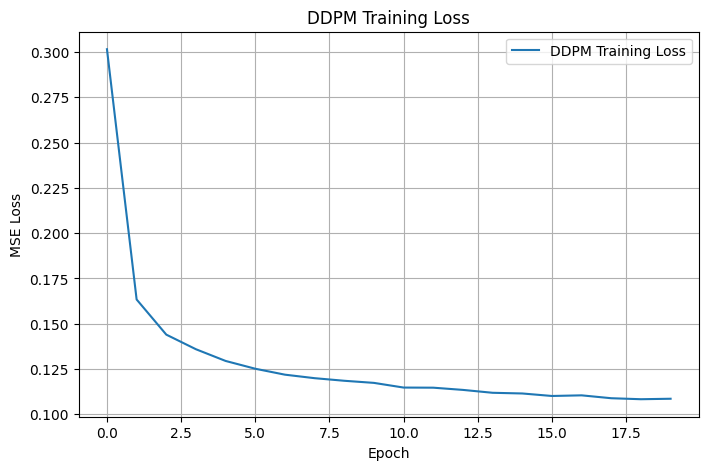

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_ddpm["loss"],
    label="DDPM Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training Loss")
plt.legend()
plt.grid()

plt.savefig(
    os.path.join(PROJECT_PATH, "results", "figures", "ddpm_loss.png"),
    dpi=150
)

plt.show()

In [ ]:
@torch.no_grad()
def generate_ddpm(num_images=16):
    ddpm_model.eval()
    #mulai dari noise acak
    gambar = torch.randn(
        num_images, 1, 28, 28
    ).to(device)

    #simpan beberapa tahapan proses denoising
    trajectory = {}
    timestep_simpan = [199, 150, 100, 50, 20, 0]

    for t in reversed(range(T)):
        waktu = torch.full(
            (num_images,),
            t,
            device=device,
            dtype=torch.long
        )

        #prediksi noise
        prediksi_noise = ddpm_model(gambar, waktu)

        alpha_t = alpha[t]
        beta_t = beta[t]
        alpha_bar_t = alpha_bar[t]

        # rata-rata posterior
        gambar = (1 / torch.sqrt(alpha_t)) * (
            gambar -
            (beta_t / torch.sqrt(1 - alpha_bar_t))
            * prediksi_noise
        )


        # Tambahkan noise selama t > 0
        if t > 0:
            noise = torch.randn_like(gambar)
            gambar = (
                gambar +
                torch.sqrt(posterior_variance[t]) * noise
            )
        if t in timestep_simpan:
            trajectory[t] = gambar[:8].detach().cpu().clone()
    return gambar, trajectory


gambar_hasil_ddpm, trajectory_ddpm = generate_ddpm(16)

print("Generated images:", gambar_hasil_ddpm.shape)

Generated images: torch.Size([16, 1, 28, 28])


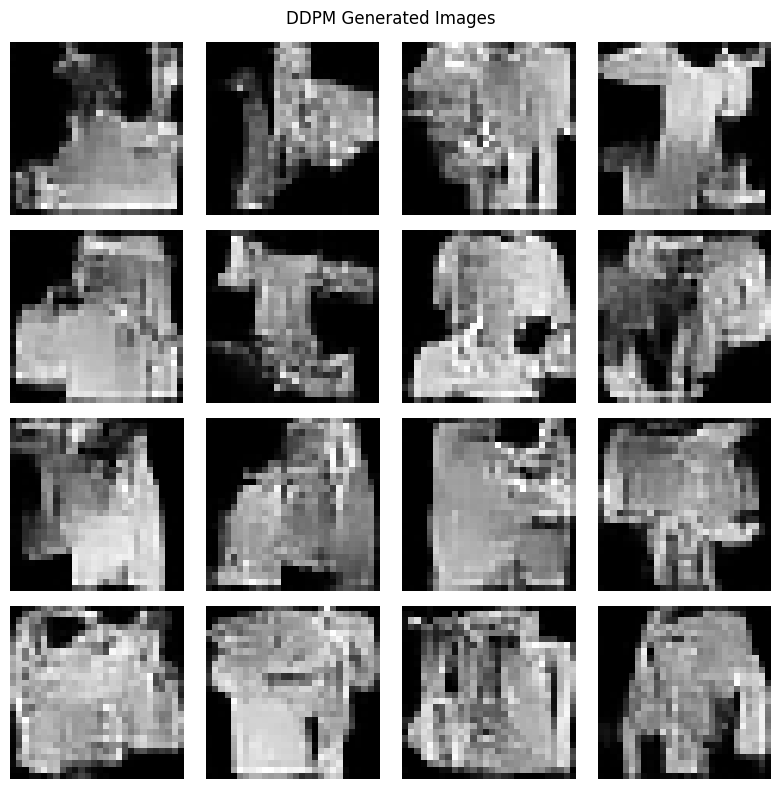

In [ ]:
#ubah rentang gambar dari [-1, 1] menjadi [0, 1]
gambar_tampil = (
    gambar_hasil_ddpm.clamp(-1, 1) + 1
) / 2

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(
        gambar_tampil[i].squeeze().cpu(),
        cmap="gray"
    )
    ax.axis("off")

plt.suptitle("DDPM Generated Images")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "ddpm_generated.png"
    ),
    dpi=150
)

plt.show()

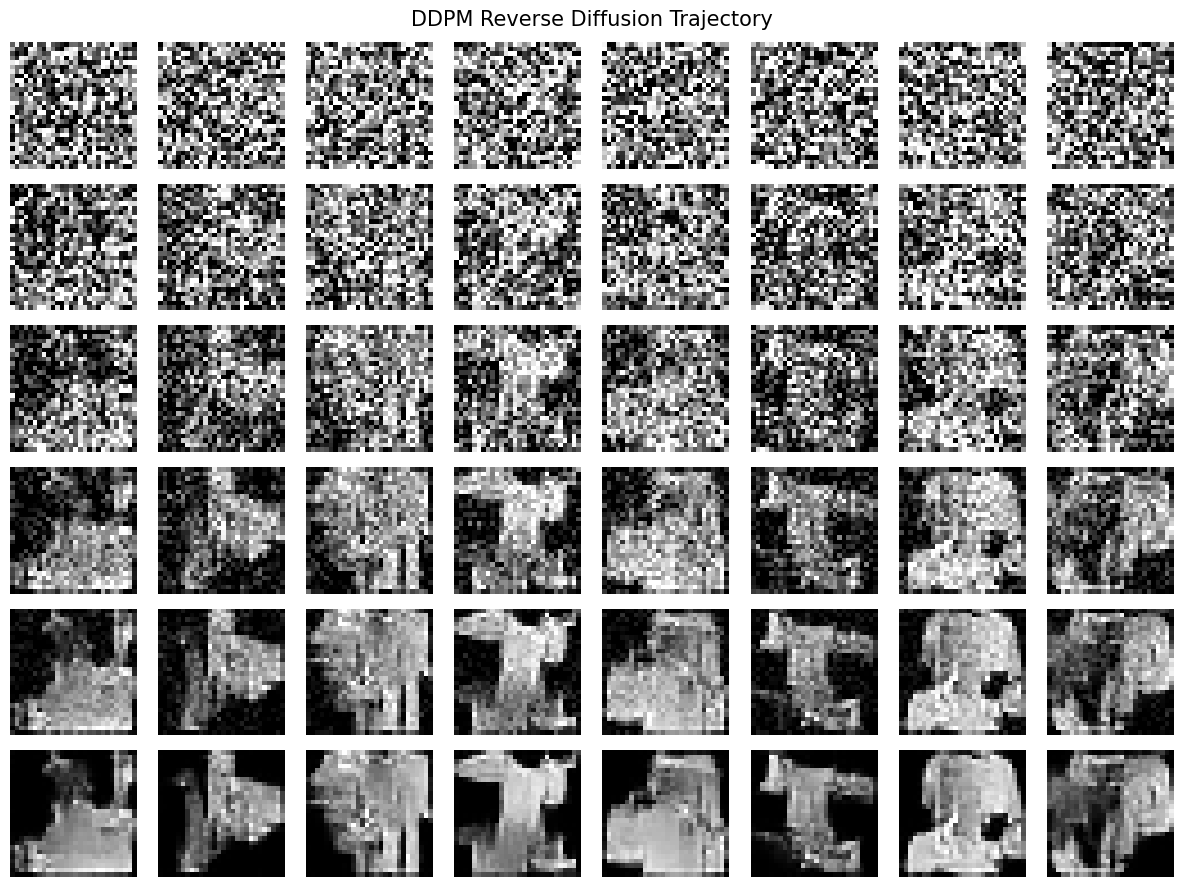

In [ ]:
#Visualisasi proses denoising
timestep_simpan = [199, 150, 100, 50, 20, 0]

fig, axes = plt.subplots(
    len(timestep_simpan),
    8,
    figsize=(12, 9)
)

for row, t in enumerate(timestep_simpan):
    gambar_tahap = trajectory_ddpm[t]
    gambar_tahap = (
        gambar_tahap.clamp(-1, 1) + 1
    ) / 2
    for col in range(8):
        axes[row, col].imshow(
            gambar_tahap[col].squeeze(),
            cmap="gray"
        )
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(
        f"t={t}",
        fontsize=11
    )

plt.suptitle(
    "DDPM Reverse Diffusion Trajectory",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "ddpm_denoising_trajectory.png"
    ),
    dpi=150
)

plt.show()

# MLP Classifier

In [ ]:
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/mlp_classifier.py

import torch
import torch.nn as nn

class MLPClassifier(nn.Module):

    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        h1 = self.relu(self.fc1(x))
        z = self.relu(self.fc2(h1))
        output = self.fc3(z)

        return output, z

Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/mlp_classifier.py


In [ ]:
from src.models.mlp_classifier import MLPClassifier

mlp_model = MLPClassifier().to(device)

EPOCHS_MLP = 20
LEARNING_RATE_MLP = 0.001
criterion_mlp = nn.CrossEntropyLoss()
optimizer_mlp = optim.Adam(
    mlp_model.parameters(),
    lr=LEARNING_RATE_MLP
)

history_mlp = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

checkpoint_mlp = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "mlp_classifier.pth"
)

print("MLP Classifier berhasil dibuat!")
print("Device:", device)

MLP Classifier berhasil dibuat!
Device: cuda


In [ ]:
from tqdm.auto import tqdm

for epoch in range(EPOCHS_MLP):

    mlp_model.train()
    total_loss = 0
    total_benar = 0
    total_data = 0

    for gambar, label in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS_MLP}"
    ):
        gambar = gambar.to(device)
        label = label.to(device)
        output, z = mlp_model(gambar)
        loss = criterion_mlp(output, label)
        optimizer_mlp.zero_grad()
        loss.backward()
        optimizer_mlp.step()
        total_loss += loss.item()
        prediksi = torch.argmax(output, dim=1)
        total_benar += (prediksi == label).sum().item()
        total_data += label.size(0)

    train_loss = total_loss / len(train_loader)
    train_accuracy = total_benar / total_data

    #validation
    mlp_model.eval()

    val_total_loss = 0
    val_total_benar = 0
    val_total_data = 0

    with torch.no_grad():
        for gambar, label in val_loader:
            gambar = gambar.to(device)
            label = label.to(device)
            output, z = mlp_model(gambar)
            loss = criterion_mlp(output, label)
            val_total_loss += loss.item()
            prediksi = torch.argmax(output, dim=1)
            val_total_benar += (
                prediksi == label
            ).sum().item()
            val_total_data += label.size(0)

    val_loss = val_total_loss / len(val_loader)
    val_accuracy = val_total_benar / val_total_data

    history_mlp["train_loss"].append(train_loss)
    history_mlp["val_loss"].append(val_loss)

    history_mlp["train_accuracy"].append(train_accuracy)
    history_mlp["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{EPOCHS_MLP} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy*100:.2f}%"
    )

torch.save(
    mlp_model.state_dict(),
    checkpoint_mlp
)

print("Training MLP Classifier selesai!")

Epoch 1/20:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.5927 | Train Accuracy: 79.14% | Val Loss: 0.4479 | Val Accuracy: 84.64%


Epoch 2/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()    self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Epoch 2/20 | Train Loss: 0.4050 | Train Accuracy: 85.68% | Val Loss: 0.3907 | Val Accuracy: 85.99%


Epoch 3/20:   0%|          | 0/438 [00:00<?, ?it/s]

... (49 outputs left out)

Epoch 19/20 | Train Loss: 0.1861 | Train Accuracy: 93.04% | Val Loss: 0.3278 | Val Accuracy: 89.31%


Epoch 20/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
if w.is_alive():    
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a

Epoch 20/20 | Train Loss: 0.1780 | Train Accuracy: 93.30% | Val Loss: 0.3112 | Val Accuracy: 89.99%
Training MLP Classifier selesai!


In [ ]:
mlp_model.eval()

test_total_benar = 0
test_total_data = 0

with torch.no_grad():

    for gambar, label in test_loader:
        gambar = gambar.to(device)
        label = label.to(device)
        output, z = mlp_model(gambar)
        prediksi = torch.argmax(output, dim=1)
        test_total_benar += (
            prediksi == label
        ).sum().item()

        test_total_data += label.size(0)
test_accuracy = test_total_benar / test_total_data

print(f"Test Accuracy: {test_accuracy*100:.2f}%")

if test_accuracy >= 0.88:
    print("Target akurasi minimal 88% tercapai!")
else:
    print("Target belum tercapai, perlu evaluasi training.")

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>AssertionError: can only test a child process

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    Exception ignored in: self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>

Traceback (most recent call last):
  File "/usr/local/lib/pyt

Test Accuracy: 89.24%
Target akurasi minimal 88% tercapai!


In [ ]:
mlp_model.eval()

test_total_benar = 0
test_total_data = 0

with torch.no_grad():
    for gambar, label in test_loader:
        gambar = gambar.to(device)
        label = label.to(device)
        output, z = mlp_model(gambar)
        prediksi = torch.argmax(output, dim=1)
        test_total_benar += (
            prediksi == label
        ).sum().item()

        test_total_data += label.size(0)
test_accuracy = test_total_benar / test_total_data
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

if test_accuracy >= 0.88:
    print("Target akurasi minimal 88% tercapai!")
else:
    print("Target belum tercapai, perlu evaluasi training.")

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a

Test Accuracy: 89.24%
Target akurasi minimal 88% tercapai!


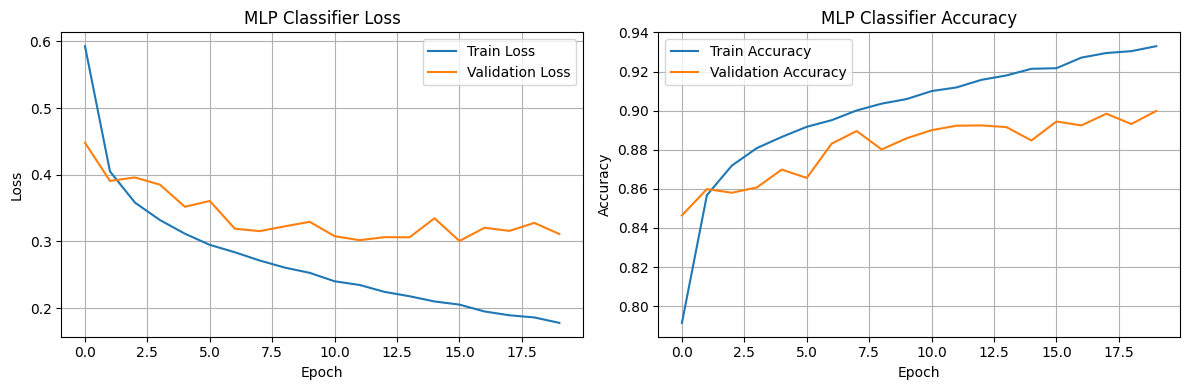

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_mlp["train_loss"],
    label="Train Loss"
)

axes[0].plot(
    history_mlp["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("MLP Classifier Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].plot(
    history_mlp["train_accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    history_mlp["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("MLP Classifier Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "mlp_classifier_training.png"
    ),
    dpi=150
)

plt.show()

In [ ]:
#proyeksi balik bobot dari vektor kelas
mlp_model.eval()

#membuat 10 vektor one-hot untuk 10 kelas
one_hot = torch.eye(10).to(device)

with torch.no_grad():
    z_hat = torch.relu(     # Proyeksi balik W3
        one_hot @ mlp_model.fc3.weight
    )
    h1_hat = torch.relu(    # Proyeksi balik W2
        z_hat @ mlp_model.fc2.weight
    )
    x_hat = torch.sigmoid(    # Proyeksi balik W1
        h1_hat @ mlp_model.fc1.weight
    )

#ubah menjadi format gambar 28x28
gambar_transpose = x_hat.view(-1, 1, 28, 28)

print("Hasil proyeksi:", gambar_transpose.shape)

Hasil proyeksi: torch.Size([10, 1, 28, 28])


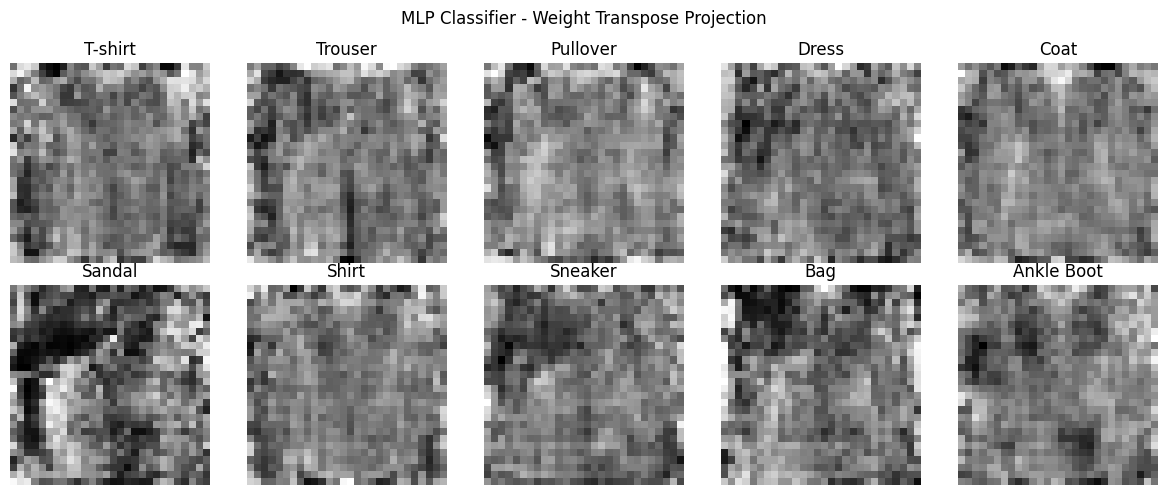

In [ ]:
#Visualisasi hasil transpose bobot
nama_kelas = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flatten()):

    ax.imshow(
        gambar_transpose[i].squeeze().cpu(),
        cmap="gray"
    )

    ax.set_title(nama_kelas[i])
    ax.axis("off")

plt.suptitle("MLP Classifier - Weight Transpose Projection")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "mlp_weight_transpose.png"
    ),
    dpi=150
)

plt.show()

In [ ]:
#Proyeksi balik dari latent features gambar asli
mlp_model.eval()

#ambil 8 gambar dari test set
gambar_asli, label_asli = next(iter(test_loader))

gambar_asli = gambar_asli[:8].to(device)
label_asli = label_asli[:8]

with torch.no_grad():
    #ekstrak latent features dari gambar asli
    output, z_mlp = mlp_model(gambar_asli)
    #proyeksi balik menggunakan transpose bobot
    h1_hat = torch.relu(
        z_mlp @ mlp_model.fc2.weight
    )
    x_hat = torch.sigmoid(
        h1_hat @ mlp_model.fc1.weight
    )
    gambar_rekonstruksi_transpose = x_hat.view(
        -1, 1, 28, 28
    )

print("Latent feature shape:", z_mlp.shape)
print("Reconstruction shape:", gambar_rekonstruksi_transpose.shape)

Latent feature shape: torch.Size([8, 64])
Reconstruction shape: torch.Size([8, 1, 28, 28])


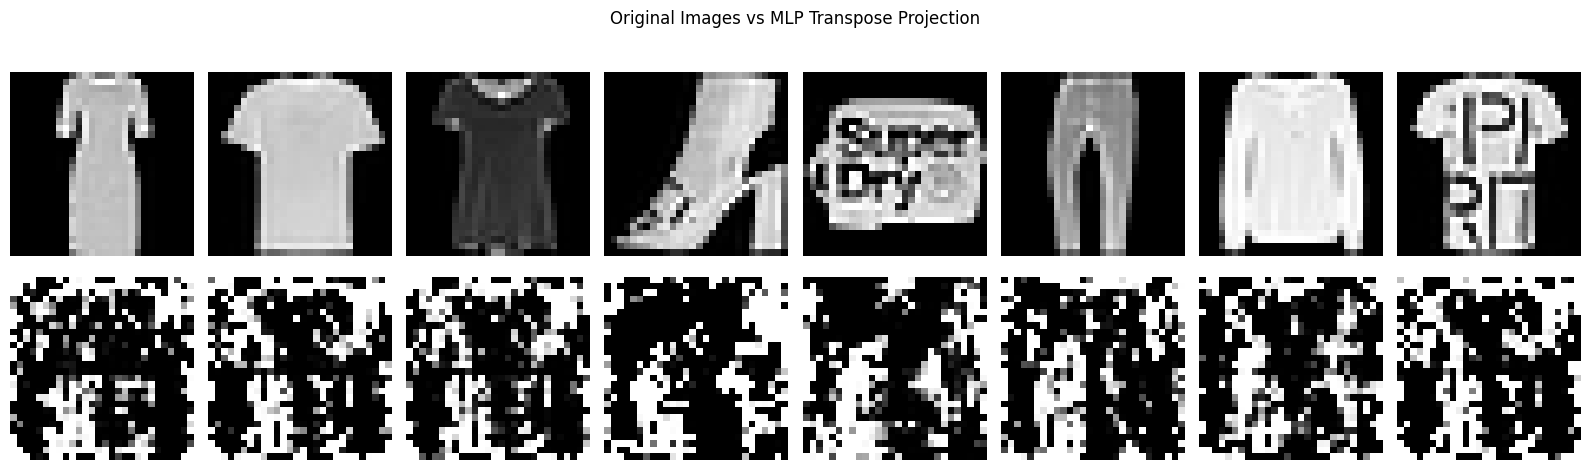

In [ ]:
#membandingkan gambar asli dan hasil proyeksi
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):
    #gambar asli
    axes[0, i].imshow(
        gambar_asli[i].squeeze().cpu(),
        cmap="gray"
    )
    axes[0, i].axis("off")
    #hasil transpose projection
    axes[1, i].imshow(
        gambar_rekonstruksi_transpose[i].squeeze().cpu(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Transpose")

plt.suptitle("Original Images vs MLP Transpose Projection")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "mlp_latent_transpose.png"
    ),
    dpi=150
)

plt.show()

In [ ]:
#bekukan seluruh parameter MLP Classifier
for parameter in mlp_model.parameters():
    parameter.requires_grad = False

mlp_model.eval()

print("MLP Classifier berhasil dibekukan!")

#pastikan bahwa semua parameter sudah frozen
for nama, parameter in mlp_model.named_parameters():
    print(nama, parameter.requires_grad)

MLP Classifier berhasil dibekukan!
fc1.weight False
fc1.bias False
fc2.weight False
fc2.bias False
fc3.weight False
fc3.bias False


In [ ]:
#membuat decoder MLP
%%writefile /content/drive/MyDrive/DeepLearning_TakeHome/src/models/mlp_decoder.py

import torch
import torch.nn as nn


class MLPDecoder(nn.Module):
    def __init__(self):
        super(MLPDecoder, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.network(z)
        x = x.view(-1, 1, 28, 28)
        return x

Writing /content/drive/MyDrive/DeepLearning_TakeHome/src/models/mlp_decoder.py


In [ ]:
from src.models.mlp_decoder import MLPDecoder

mlp_decoder = MLPDecoder().to(device)
EPOCHS_DECODER = 20
LEARNING_RATE_DECODER = 0.001
optimizer_decoder = optim.Adam(
    mlp_decoder.parameters(),
    lr=LEARNING_RATE_DECODER
)

criterion_decoder = nn.MSELoss()
history_decoder = {
    "train_loss": [],
    "val_loss": []
}
checkpoint_decoder = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "mlp_frozen_decoder.pth"
)

print("Frozen Latent Decoder berhasil dibuat!")

Frozen Latent Decoder berhasil dibuat!


In [ ]:
#Training Frozen Latent Decoder
for epoch in range(EPOCHS_DECODER):
    mlp_model.eval()
    mlp_decoder.train()
    total_loss = 0

    for gambar, _ in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS_DECODER}"
    ):
        gambar = gambar.to(device)
        #ekstraksi fitur laten tanpa melatih classifier
        with torch.no_grad():
            _, z_mlp = mlp_model(gambar)

        #rekonstruksi menggunakan decoder baru
        hasil_rekonstruksi = mlp_decoder(z_mlp)

        loss = criterion_decoder(
            hasil_rekonstruksi,
            gambar
        )

        optimizer_decoder.zero_grad()
        loss.backward()
        optimizer_decoder.step()
        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)

    #validation =
    mlp_decoder.eval()

    total_val_loss = 0

    with torch.no_grad():
        for gambar, _ in val_loader:
            gambar = gambar.to(device)
            _, z_mlp = mlp_model(gambar)
            hasil_rekonstruksi = mlp_decoder(z_mlp)
            loss = criterion_decoder(
                hasil_rekonstruksi,
                gambar
            )
            total_val_loss += loss.item()
    val_loss = total_val_loss / len(val_loader)

    history_decoder["train_loss"].append(train_loss)
    history_decoder["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS_DECODER}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

torch.save(
    mlp_decoder.state_dict(),
    checkpoint_decoder
)

print("Training Frozen Latent Decoder selesai!")

Epoch 1/20:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 0.035610 | Val Loss: 0.026664


Epoch 2/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
if w.is_alive():
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        self._shutdown_workers()assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
AssertionError    : if w.is_alive():can only test a child process

  File "/usr/lib/

Epoch [2/20] | Train Loss: 0.024563 | Val Loss: 0.023210


Epoch 3/20:   0%|          | 0/438 [00:00<?, ?it/s]

... (49 outputs left out)

Epoch [19/20] | Train Loss: 0.017049 | Val Loss: 0.017619


Epoch 20/20:   0%|          | 0/438 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ec78d1f80>
    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    self._shutdown_workers()    
if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Epoch [20/20] | Train Loss: 0.016976 | Val Loss: 0.017737
Training Frozen Latent Decoder selesai!


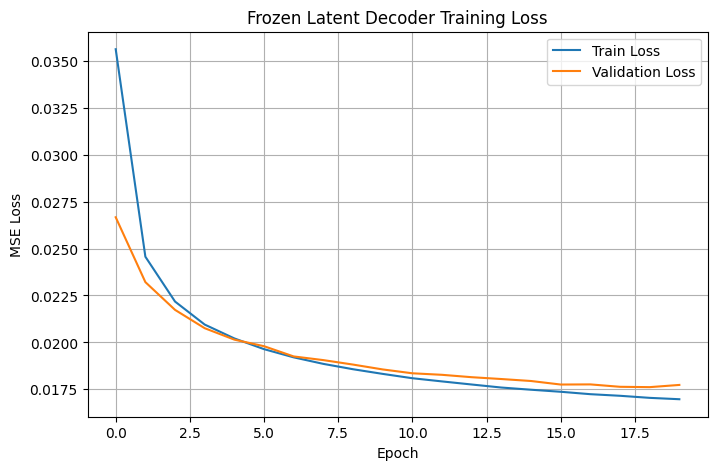

In [ ]:
#Visualisasi training loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_decoder["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_decoder["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Frozen Latent Decoder Training Loss")
plt.legend()
plt.grid()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "mlp_frozen_decoder_loss.png"
    ),
    dpi=150
)

plt.show()

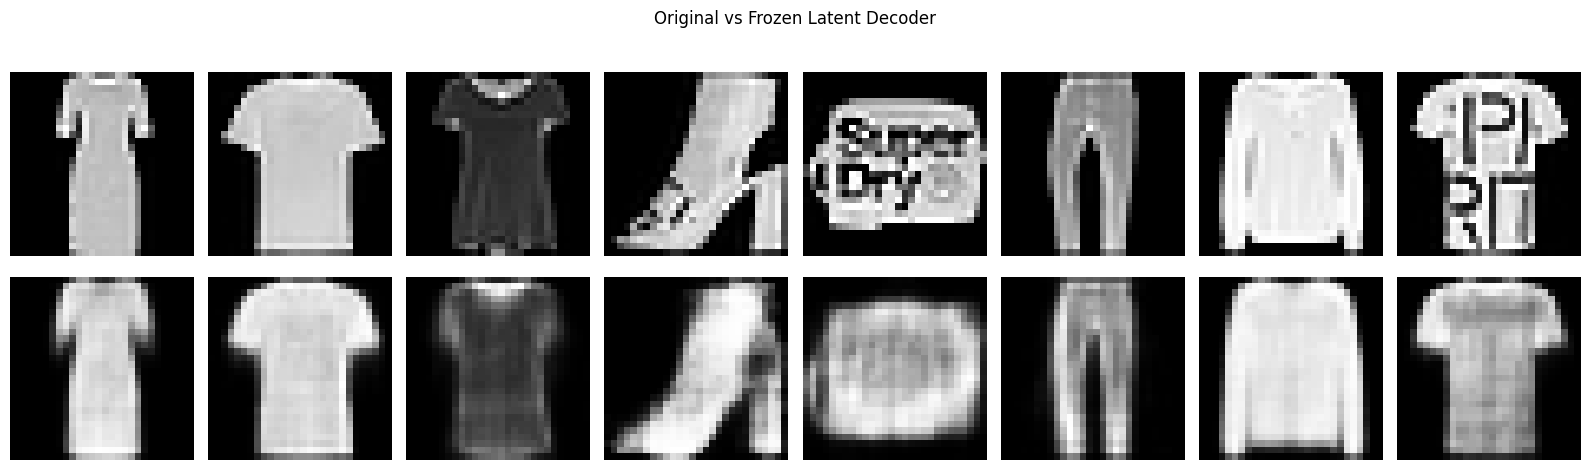

In [ ]:
#hasil rekonstruksi
mlp_model.eval()
mlp_decoder.eval()

gambar_asli, label_asli = next(iter(test_loader))
gambar_asli = gambar_asli[:8].to(device)

with torch.no_grad():
    _, z_mlp = mlp_model(gambar_asli)
    hasil_rekonstruksi = mlp_decoder(z_mlp)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):
    axes[0, i].imshow(
        gambar_asli[i].squeeze().cpu(),
        cmap="gray"
    )
    axes[0, i].axis("off")
    axes[1, i].imshow(
        hasil_rekonstruksi[i].squeeze().cpu(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("MLP Decoder")

plt.suptitle("Original vs Frozen Latent Decoder")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "mlp_frozen_decoder.png"
    ),
    dpi=150
)

plt.show()

In [ ]:
mlp_model.eval()
semua_latent = []

with torch.no_grad():
    for gambar, _ in test_loader:
        gambar = gambar.to(device)
        _, z_mlp = mlp_model(gambar)
        semua_latent.append(z_mlp)

#gabungkan
semua_latent = torch.cat(semua_latent, dim=0)

#hitung rata-rata dan standar deviasi setiap dimensi laten
mu_z = semua_latent.mean(dim=0)
sigma_z = semua_latent.std(dim=0, unbiased=False)

print("Jumlah latent features:", semua_latent.shape)
print("Mu shape:", mu_z.shape)
print("Sigma shape:", sigma_z.shape)
print("Rata-rata latent:", mu_z.mean().item())
print("Rata-rata standar deviasi:", sigma_z.mean().item())

Jumlah latent features: torch.Size([7000, 64])
Mu shape: torch.Size([64])
Sigma shape: torch.Size([64])
Rata-rata latent: 1.651090383529663
Rata-rata standar deviasi: 1.9540984630584717


In [ ]:
# Jumlah gambar yang akan dihasilkan
NUM_SAMPLES = 16

# Sampling dari distribusi Gaussian berdasarkan statistik latent MLP
noise = torch.randn(NUM_SAMPLES, 64).to(device)
z_random = mu_z + sigma_z * noise

# Masukkan ke Frozen Latent Decoder
mlp_decoder.eval()
with torch.no_grad():
    gambar_sampling_mlp = mlp_decoder(z_random)

print("Random latent shape:", z_random.shape)
print("Generated images shape:", gambar_sampling_mlp.shape)

Random latent shape: torch.Size([16, 64])
Generated images shape: torch.Size([16, 1, 28, 28])


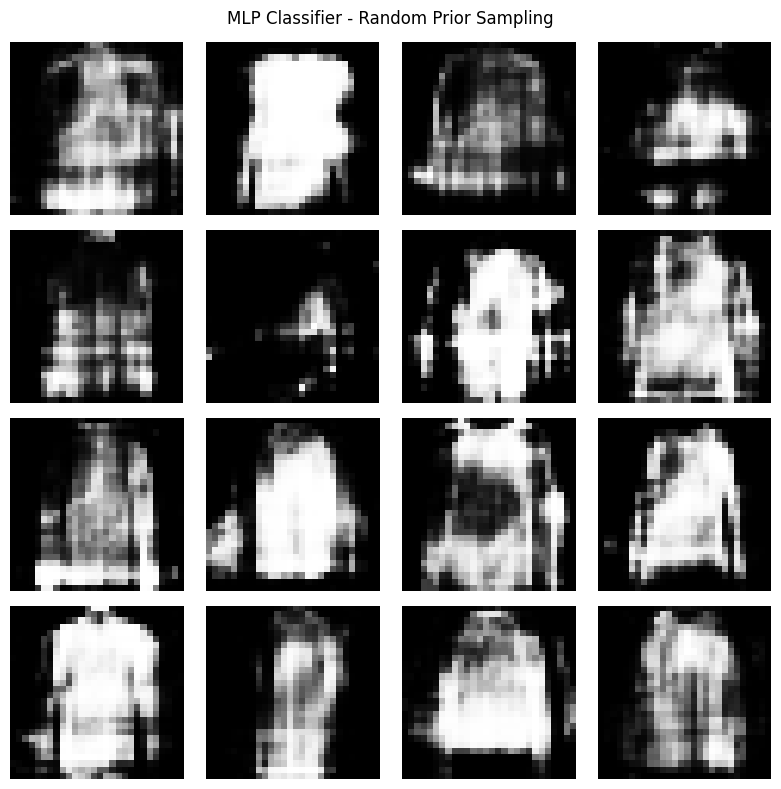

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(
        gambar_sampling_mlp[i].squeeze().cpu(),
        cmap="gray"
    )
    ax.axis("off")

plt.suptitle("MLP Classifier - Random Prior Sampling")
plt.tight_layout()
plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "results",
        "figures",
        "mlp_random_sampling.png"
    ),
    dpi=150
)

plt.show()

In [ ]:
#cek
gambar_test, label_test = next(iter(test_loader))

gambar_test = gambar_test[:8].to(device)

with torch.no_grad():
    hasil_ae, z_ae = autoencoder(gambar_test)

    output_mlp, z_mlp = mlp_model(gambar_test)

    hasil_decoder = mlp_decoder(z_mlp)

print("Original:", gambar_test.shape)
print("Vanilla AE:", hasil_ae.shape)
print("Vanilla AE Latent:", z_ae.shape)
print("MLP output:", output_mlp.shape)
print("MLP latent:", z_mlp.shape)
print("Frozen Decoder:", hasil_decoder.shape)

Original: torch.Size([8, 1, 28, 28])
Vanilla AE: torch.Size([8, 1, 28, 28])
Vanilla AE Latent: torch.Size([8, 64])
MLP output: torch.Size([8, 10])
MLP latent: torch.Size([8, 64])
Frozen Decoder: torch.Size([8, 1, 28, 28])


## Visualisasi perbandingan rekonstruksi

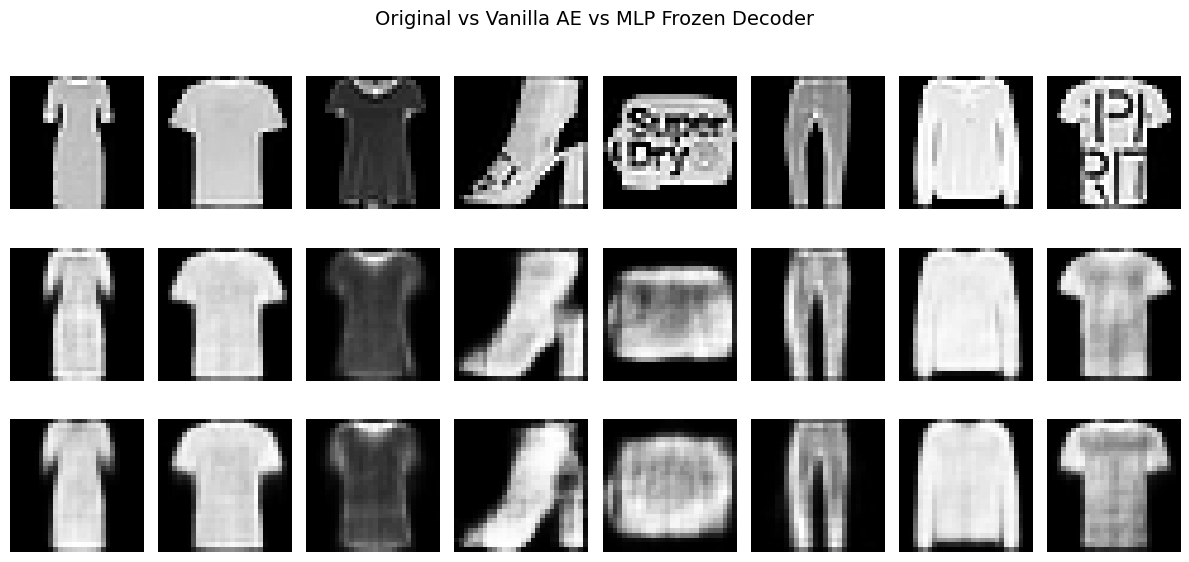

Gambar berhasil disimpan: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/mlp_ae_decoder_comparison.png


In [ ]:
plt.figure(figsize=(12, 6))

for i in range(8):
    #ori image
    plt.subplot(3, 8, i + 1)
    plt.imshow(gambar_test[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("Original", fontsize=11)

    #Vanilla AE Reconstruction
    plt.subplot(3, 8, i + 9)
    plt.imshow(hasil_ae[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("Vanilla AE", fontsize=11)

    #MLP Frozen Decoder
    plt.subplot(3, 8, i + 17)
    plt.imshow(hasil_decoder[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("MLP Decoder", fontsize=11)

plt.suptitle("Original vs Vanilla AE vs MLP Frozen Decoder", fontsize=14)
plt.tight_layout()

#save
save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "mlp_ae_decoder_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Gambar berhasil disimpan:", save_path)

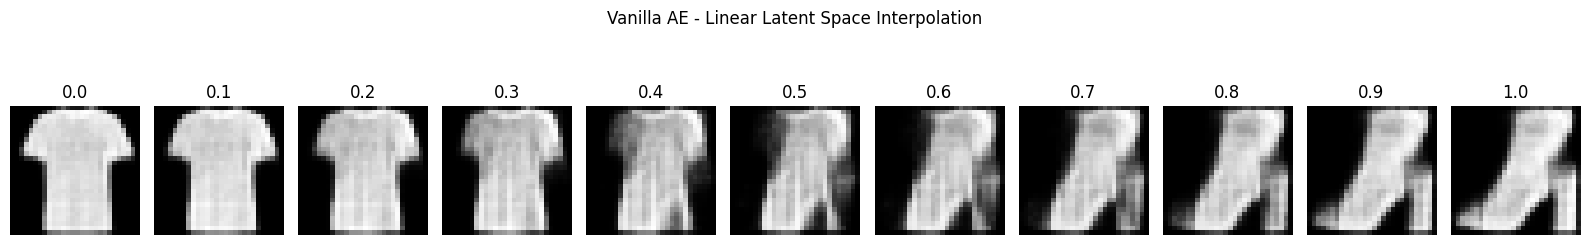

Hasil disimpan: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/vanilla_ae_interpolation.png


In [ ]:
#cari 2 gambar dengan label berbeda
gambar_1 = None
gambar_2 = None

for i in range(len(test_set)):
    img, label = test_set[i]
    if label == 0 and gambar_1 is None:
        gambar_1 = img
    if label == 9 and gambar_2 is None:
        gambar_2 = img
    if gambar_1 is not None and gambar_2 is not None:
        break

#masukkan gambar ke device
gambar_1 = gambar_1.unsqueeze(0).to(device)
gambar_2 = gambar_2.unsqueeze(0).to(device)

#ambil latent representation
with torch.no_grad():
    z1 = autoencoder.encoder(gambar_1)
    z2 = autoencoder.encoder(gambar_2)

    # buat 11 titik interpolasi
    alphas = torch.linspace(0, 1, 11).to(device)
    z_interpolasi = torch.stack([
        (1 - alpha) * z1.squeeze(0) + alpha * z2.squeeze(0)
        for alpha in alphas
    ])

    #decode semua latent vector
    hasil_interpolasi = autoencoder.decoder(z_interpolasi)
    hasil_interpolasi = hasil_interpolasi.view(-1, 1, 28, 28)

#visualisasinya
plt.figure(figsize=(16, 3))

for i in range(11):
    plt.subplot(1, 11, i + 1)
    plt.imshow(
        hasil_interpolasi[i].cpu().squeeze(),
        cmap="gray"
    )
    plt.title(f"{alphas[i].item():.1f}")
    plt.axis("off")

plt.suptitle("Vanilla AE - Linear Latent Space Interpolation")
plt.tight_layout()

#save hasilnya
save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "vanilla_ae_interpolation.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hasil disimpan:", save_path)

### Eksperimen: Linear Latent Space Interpolation - Sparse AE

In [ ]:
from src.models.sparse_autoencoder import SparseAutoencoder

sparse_ae = SparseAutoencoder(latent_dim=64).to(device)
checkpoint_sparse = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "sparse_ae.pth"
)

sparse_ae.load_state_dict(
    torch.load(checkpoint_sparse, map_location=device)
)

sparse_ae.eval()

print("Sparse Autoencoder berhasil dimuat!")

Sparse Autoencoder berhasil dimuat!


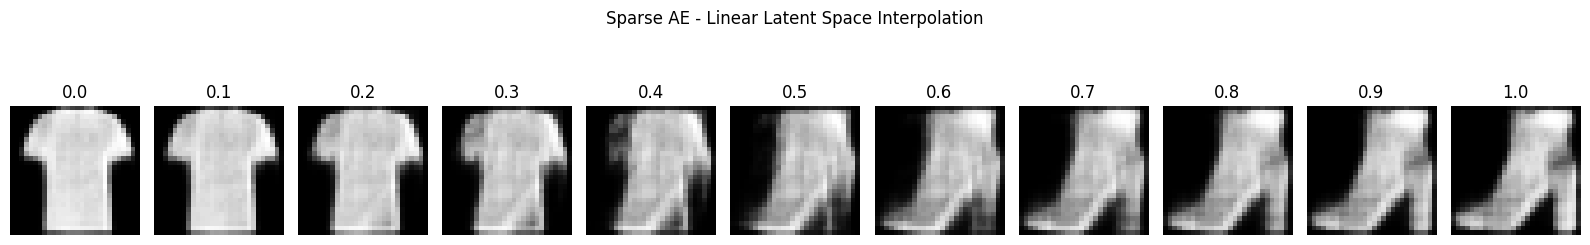

Hasil disimpan: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/sparse_ae_interpolation.png


In [ ]:
#cari 2 gambar: T-shirt (label 0) dan Ankle Boot (label 9)
gambar_1 = None
gambar_2 = None

for i in range(len(test_set)):
    img, label = test_set[i]
    if label == 0 and gambar_1 is None:
        gambar_1 = img
    if label == 9 and gambar_2 is None:
        gambar_2 = img
    if gambar_1 is not None and gambar_2 is not None:
        break

gambar_1 = gambar_1.unsqueeze(0).to(device)
gambar_2 = gambar_2.unsqueeze(0).to(device)

#ambil latent representation
with torch.no_grad():
    z1 = sparse_ae.encoder(gambar_1)
    z2 = sparse_ae.encoder(gambar_2)

    #buat 11 titik interpolasi
    alphas = torch.linspace(0, 1, 11).to(device)

    z_interpolasi = torch.stack([
        (1 - alpha) * z1.squeeze(0) + alpha * z2.squeeze(0)
        for alpha in alphas
    ])

    #ubah latent vector menjadi gambar
    hasil_interpolasi = sparse_ae.decoder(z_interpolasi)
    hasil_interpolasi = hasil_interpolasi.view(-1, 1, 28, 28)

#visualisasi
plt.figure(figsize=(16, 3))

for i in range(11):
    plt.subplot(1, 11, i + 1)
    plt.imshow(
        hasil_interpolasi[i].cpu().squeeze(),
        cmap="gray"
    )
    plt.title(f"{alphas[i].item():.1f}")
    plt.axis("off")

plt.suptitle("Sparse AE - Linear Latent Space Interpolation")
plt.tight_layout()

#save
save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "sparse_ae_interpolation.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hasil disimpan:", save_path)

### Eksperimen: Linear Latent Space Interpolation - VAE

In [ ]:
from src.models.vae import VariationalAutoencoder

vae_model = VariationalAutoencoder(latent_dim=64).to(device)
checkpoint_vae = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "vae.pth"
)

vae_model.load_state_dict(
    torch.load(checkpoint_vae, map_location=device)
)

vae_model.eval()

print("VAE berhasil dimuat!")

VAE berhasil dimuat!


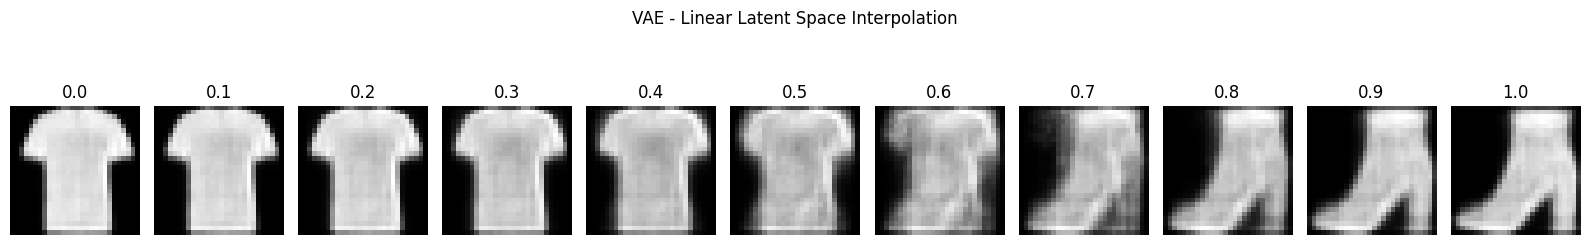

Hasil disimpan: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/vae_interpolation.png


In [ ]:
#mencari 2 gambar: T-shirt (label 0) dan Ankle Boot (label 9)
gambar_1 = None
gambar_2 = None

for i in range(len(test_set)):
    img, label = test_set[i]
    if label == 0 and gambar_1 is None:
        gambar_1 = img
    if label == 9 and gambar_2 is None:
        gambar_2 = img
    if gambar_1 is not None and gambar_2 is not None:
        break

gambar_1 = gambar_1.unsqueeze(0).to(device)
gambar_2 = gambar_2.unsqueeze(0).to(device)

#ambil mean (mu) dari kedua gambar
with torch.no_grad():
    features_1 = vae_model.encoder(gambar_1)
    mu_1 = vae_model.fc_mu(features_1)
    features_2 = vae_model.encoder(gambar_2)
    mu_2 = vae_model.fc_mu(features_2)

    #buat 11 titik interpolasi
    alphas = torch.linspace(0, 1, 11).to(device)
    z_interpolasi = torch.stack([
        (1 - alpha) * mu_1.squeeze(0) + alpha * mu_2.squeeze(0)
        for alpha in alphas
    ])

    # Decode latent vector
    hasil_interpolasi = vae_model.decoder(z_interpolasi)
    hasil_interpolasi = hasil_interpolasi.view(-1, 1, 28, 28)

#visualisasi nya
plt.figure(figsize=(16, 3))

for i in range(11):
    plt.subplot(1, 11, i + 1)

    plt.imshow(
        hasil_interpolasi[i].cpu().squeeze(),
        cmap="gray"
    )

    plt.title(f"{alphas[i].item():.1f}")
    plt.axis("off")

plt.suptitle("VAE - Linear Latent Space Interpolation")
plt.tight_layout()

#save
save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "vae_interpolation.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hasil disimpan:", save_path)

### Eksperimen: Latent Space Interpolation - Vanilla GAN

In [ ]:
from src.models.vanilla_gan import Generator

vanilla_generator = Generator(noise_dim=100).to(device)
checkpoint_gan = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "vanilla_gan_generator.pth"
)

vanilla_generator.load_state_dict(
    torch.load(checkpoint_gan, map_location=device)
)

vanilla_generator.eval()

print("Vanilla GAN Generator berhasil dimuat!")

Vanilla GAN Generator berhasil dimuat!


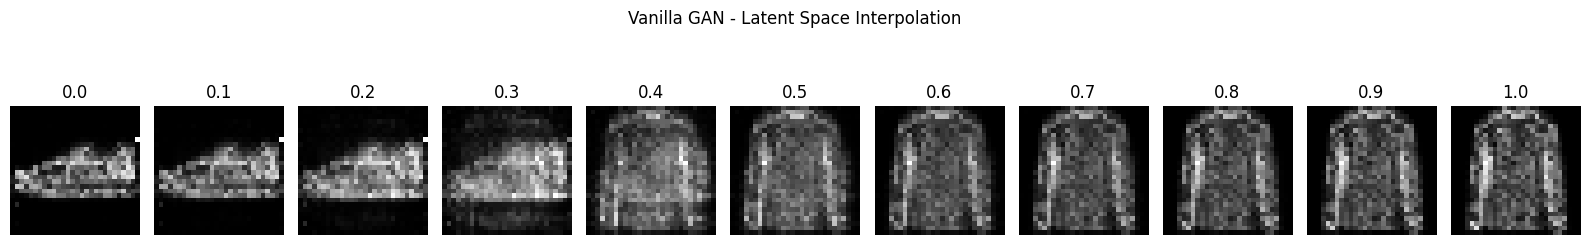

Hasil disimpan: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/vanilla_gan_interpolation.png


In [ ]:
#buat 2 random noise vector
z1 = torch.randn(1, 100).to(device)
z2 = torch.randn(1, 100).to(device)
# Membuat 11 titik interpolasi
alphas = torch.linspace(0, 1, 11).to(device)

with torch.no_grad():

    z_interpolasi = torch.stack([
        (1 - alpha) * z1.squeeze(0) + alpha * z2.squeeze(0)
        for alpha in alphas
    ])

    #generate gambar
    hasil_interpolasi = vanilla_generator(z_interpolasi)

    #ubah rentang [-1, 1] menjadi [0, 1]
    hasil_interpolasi = (hasil_interpolasi + 1) / 2

#visualisasinya
plt.figure(figsize=(16, 3))

for i in range(11):
    plt.subplot(1, 11, i + 1)
    plt.imshow(
        hasil_interpolasi[i].cpu().squeeze(),
        cmap="gray"
    )
    plt.title(f"{alphas[i].item():.1f}")
    plt.axis("off")

plt.suptitle("Vanilla GAN - Latent Space Interpolation")
plt.tight_layout()

#save
save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "vanilla_gan_interpolation.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hasil disimpan:", save_path)

### Eksperimen: Latent Space Interpolation - DCGAN

In [ ]:
from src.models.dcgan import DCGANGenerator

dcgan_generator = DCGANGenerator(noise_dim=100).to(device)
checkpoint_dcgan = os.path.join(
    PROJECT_PATH,
    "checkpoints",
    "dcgan_generator.pth"
)

dcgan_generator.load_state_dict(
    torch.load(checkpoint_dcgan, map_location=device)
)

dcgan_generator.eval()

print("DCGAN Generator berhasil dimuat!")

DCGAN Generator berhasil dimuat!


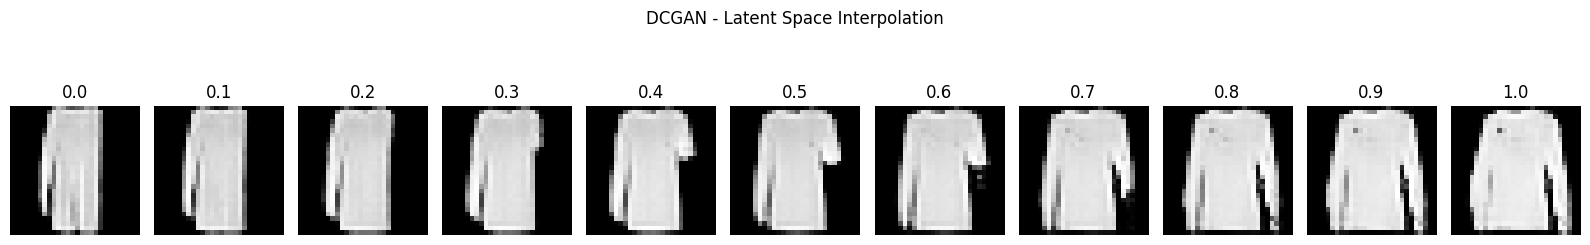

Hasil disimpan: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/dcgan_interpolation.png


In [ ]:
#buat 2 random noise vector
z1 = torch.randn(1, 100, 1, 1).to(device)
z2 = torch.randn(1, 100, 1, 1).to(device)

# Membuat 11 titik interpolasi
alphas = torch.linspace(0, 1, 11).to(device)

with torch.no_grad():
    z_interpolasi = torch.stack([
        (1 - alpha) * z1.squeeze(0) + alpha * z2.squeeze(0)
        for alpha in alphas
    ])

    #generate gambar
    hasil_interpolasi = dcgan_generator(z_interpolasi)

    #ubah rentang [-1, 1] menjadi [0, 1]
    hasil_interpolasi = (hasil_interpolasi + 1) / 2

#visualisasinya
plt.figure(figsize=(16, 3))

for i in range(11):
    plt.subplot(1, 11, i + 1)
    plt.imshow(
        hasil_interpolasi[i].cpu().squeeze(),
        cmap="gray"
    )
    plt.title(f"{alphas[i].item():.1f}")
    plt.axis("off")

plt.suptitle("DCGAN - Latent Space Interpolation")
plt.tight_layout()

#save
save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "dcgan_interpolation.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hasil disimpan:", save_path)

### Eksperimen: Training Loss Curves dan DDPM Denoising Trajectory

In [ ]:
# Melihat file yang sudah tersimpan
folder_figures = os.path.join(PROJECT_PATH, "results", "figures")
folder_metrics = os.path.join(PROJECT_PATH, "results", "metrics")

print("=== FIGURES ===")
for file in sorted(os.listdir(folder_figures)):
    print(file)

print("\n=== METRICS ===")
for file in sorted(os.listdir(folder_metrics)):
    print(file)

=== FIGURES ===
dcgan_generated.png
dcgan_interpolation.png
dcgan_loss.png
ddpm_denoising_trajectory.png
ddpm_forward_diffusion.png
ddpm_generated.png
ddpm_loss.png
mlp_ae_decoder_comparison.png
mlp_classifier_training.png
mlp_frozen_decoder.png
mlp_frozen_decoder_loss.png
mlp_latent_transpose.png
mlp_random_sampling.png
mlp_weight_transpose.png
sparse_ae_interpolation.png
sparse_ae_loss.png
sparse_ae_loss_components.png
sparse_ae_reconstruction.png
vae_generated_images.png
vae_interpolation.png
vae_loss.png
vae_loss_components.png
vae_reconstruction.png
vanilla_ae_interpolation.png
vanilla_ae_loss.png
vanilla_ae_reconstruction.png
vanilla_gan_generated.png
vanilla_gan_interpolation.png
vanilla_gan_loss.png

=== METRICS ===


## figure 5 - Training Loss & DDPM Trajectory

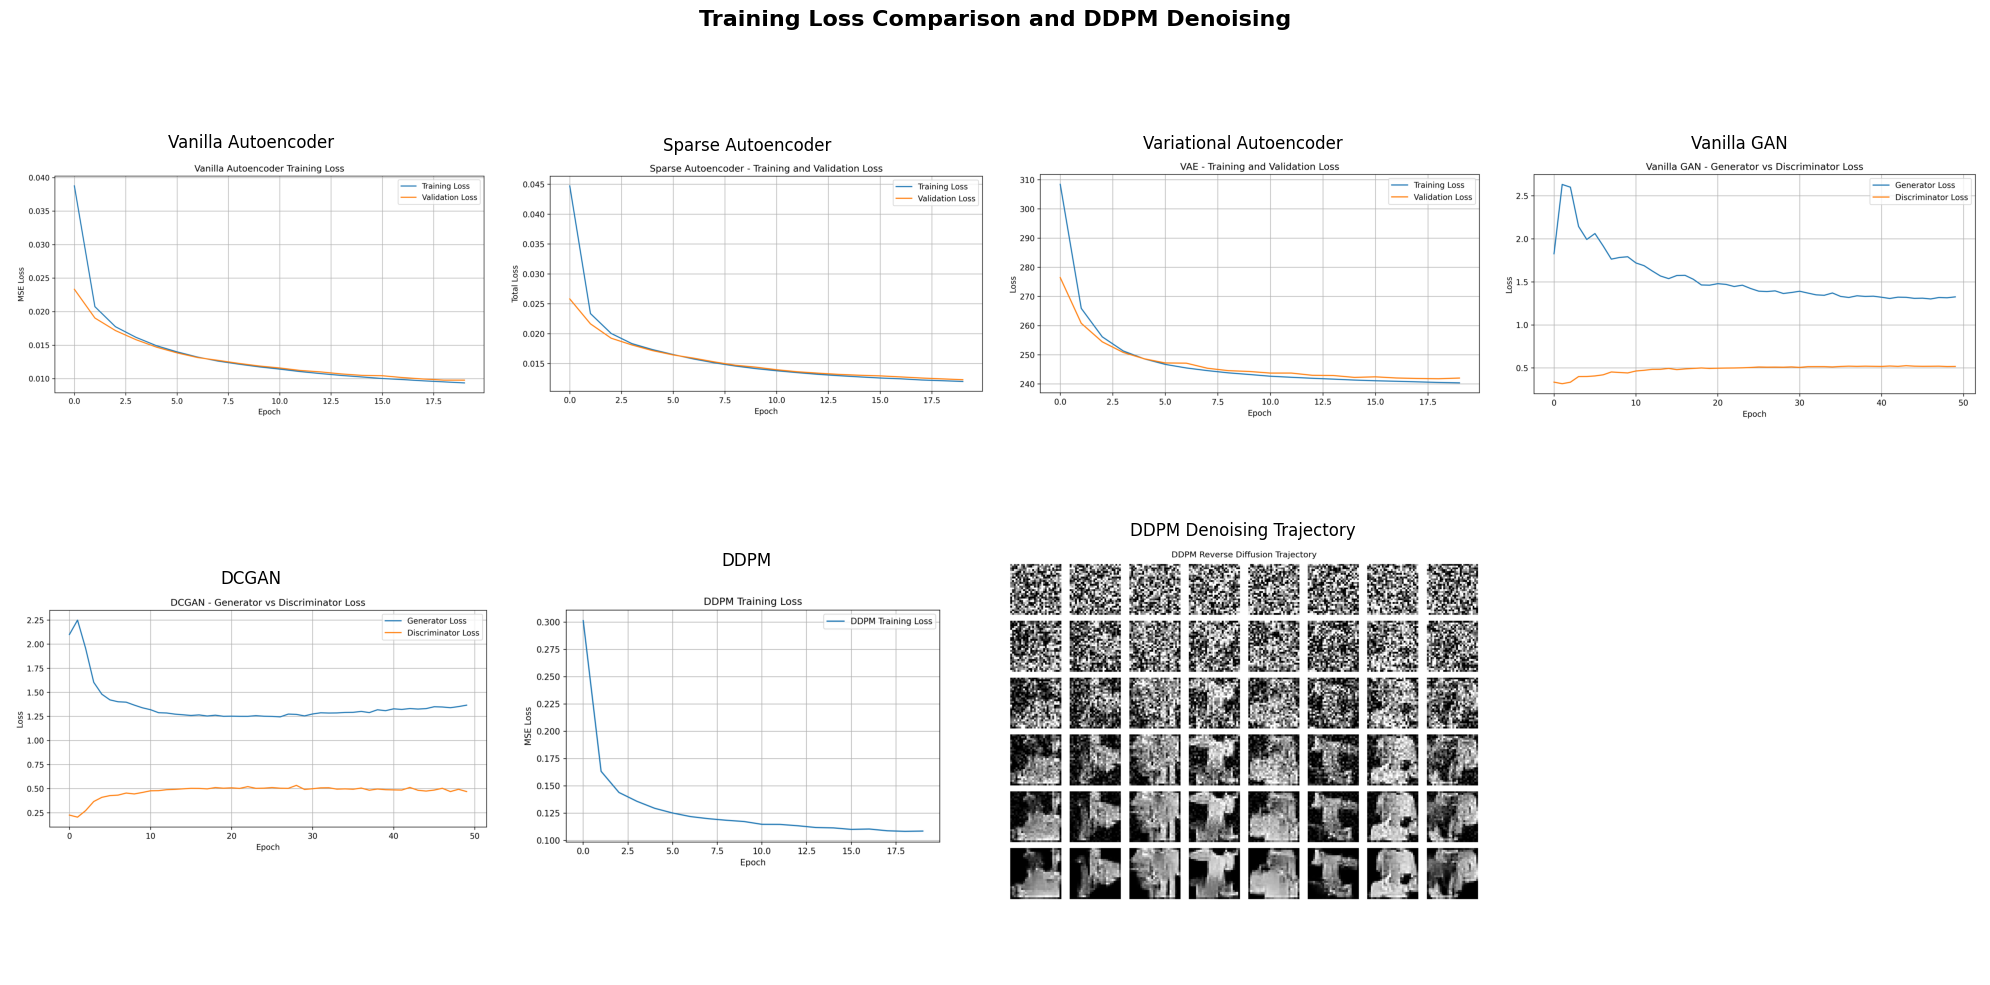

Figure 5 berhasil disimpan!
/content/drive/MyDrive/DeepLearning_TakeHome/results/figures/figure_5_training_loss_comparison.png


In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Lokasi folder gambar
folder_figures = os.path.join(PROJECT_PATH, "results", "figures")

# Daftar gambar yang akan digabungkan
daftar_gambar = [
    ("Vanilla Autoencoder", "vanilla_ae_loss.png"),
    ("Sparse Autoencoder", "sparse_ae_loss.png"),
    ("Variational Autoencoder", "vae_loss.png"),
    ("Vanilla GAN", "vanilla_gan_loss.png"),
    ("DCGAN", "dcgan_loss.png"),
    ("DDPM", "ddpm_loss.png"),
    ("DDPM Denoising Trajectory", "ddpm_denoising_trajectory.png")
]

# Membuat layout 2 baris x 4 kolom
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

axes = axes.flatten()

for i, (judul, nama_file) in enumerate(daftar_gambar):
    path_gambar = os.path.join(folder_figures, nama_file)

    if os.path.exists(path_gambar):
        gambar = mpimg.imread(path_gambar)

        axes[i].imshow(gambar)
        axes[i].set_title(judul, fontsize=12)
        axes[i].axis("off")
    else:
        axes[i].set_title(f"{judul}\nFile tidak ditemukan")
        axes[i].axis("off")

# Menonaktifkan subplot terakhir yang tidak digunakan
axes[7].axis("off")

plt.suptitle(
    "Training Loss Comparison and DDPM Denoising",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Simpan hasil
output_path = os.path.join(
    folder_figures,
    "figure_5_training_loss_comparison.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 5 berhasil disimpan!")
print(output_path)

## Figur 1 - Reconstruction Comparison

Membandingkan hasil rekonstruksi Vanilla Autoencoder, Sparse Autoencoder, dan Variational Autoencoder (VAE) terhadap gambar asli Fashion-MNIST.

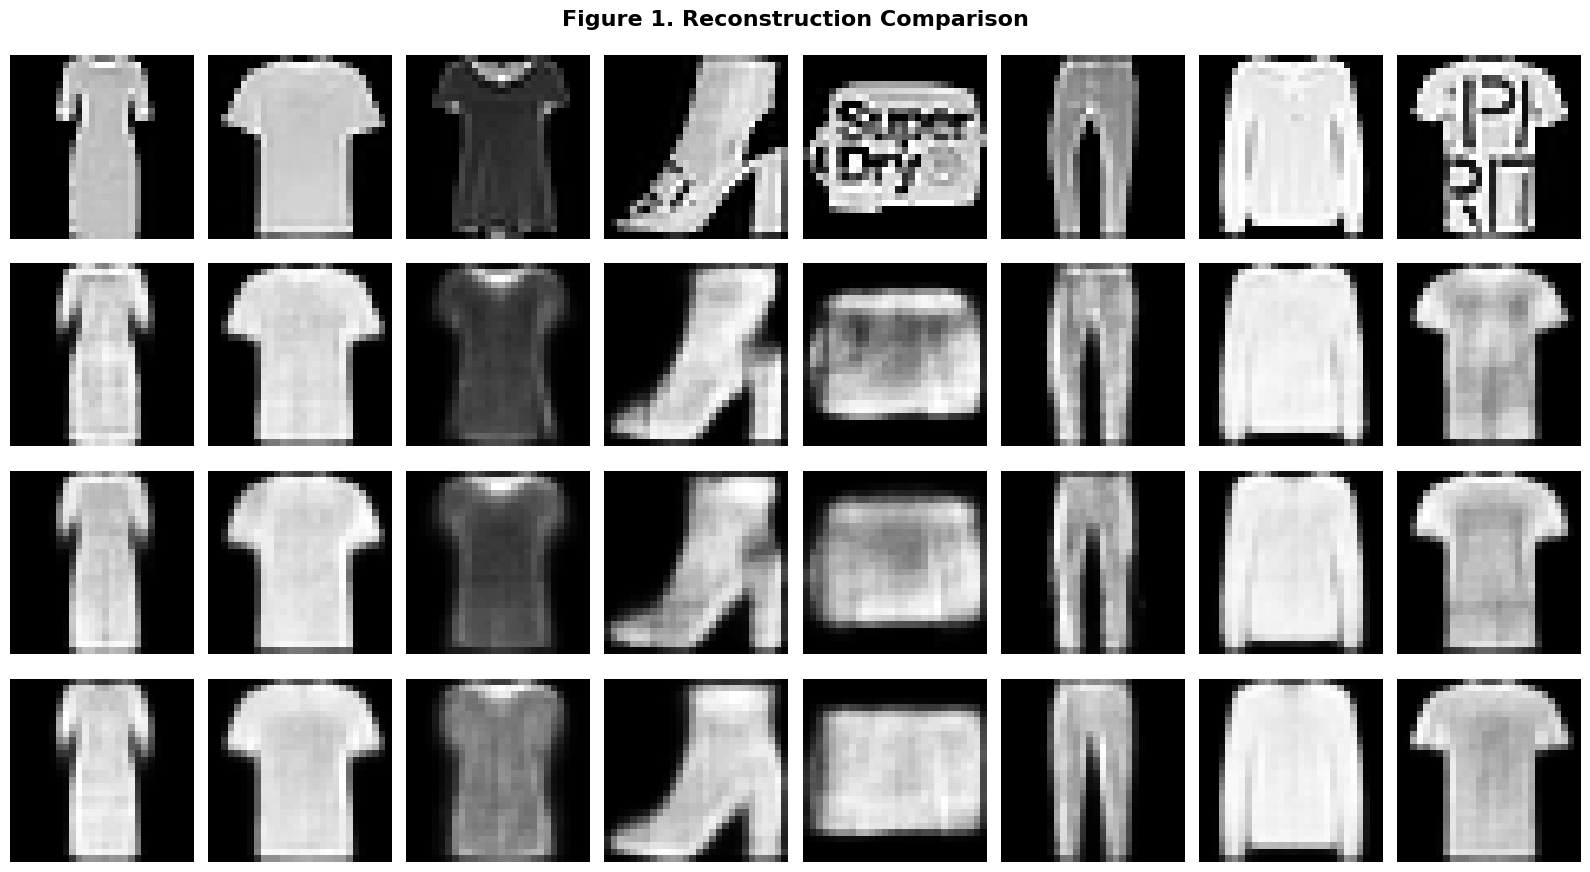

Figure 1 berhasil disimpan!
Lokasi: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/figure_1_reconstruction_comparison.png


In [ ]:
gambar_test, label_test = next(iter(test_loader))
gambar_asli = gambar_test[:8].to(device)

autoencoder.eval()
sparse_ae.eval()
vae_model.eval()

#rekonstruksi menggunakan ketiga model
with torch.no_grad():
    hasil_vanilla, _ = autoencoder(gambar_asli)
    hasil_sparse, _ = sparse_ae(gambar_asli)
    hasil_vae, mu, logvar, z = vae_model(gambar_asli)

hasil_semua = [
    gambar_asli,
    hasil_vanilla,
    hasil_sparse,
    hasil_vae
]

judul_baris = [
    "Original",
    "Vanilla AE",
    "Sparse AE",
    "VAE"
]

#buat grid 4 baris x 8 kolom
fig, axes = plt.subplots(4, 8, figsize=(16, 9))

for baris in range(4):
    for kolom in range(8):
        gambar = hasil_semua[baris][kolom].cpu().squeeze()
        axes[baris, kolom].imshow(
            gambar,
            cmap="gray"
        )

        axes[baris, kolom].axis("off")

        if kolom == 0:
            axes[baris, kolom].set_ylabel(
                judul_baris[baris],
                fontsize=11
            )

plt.suptitle(
    "Figure 1. Reconstruction Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

#save
output_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "figure_1_reconstruction_comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Figure 1 berhasil disimpan!")
print("Lokasi:", output_path)

## Figure 2. Random Generative Sampling

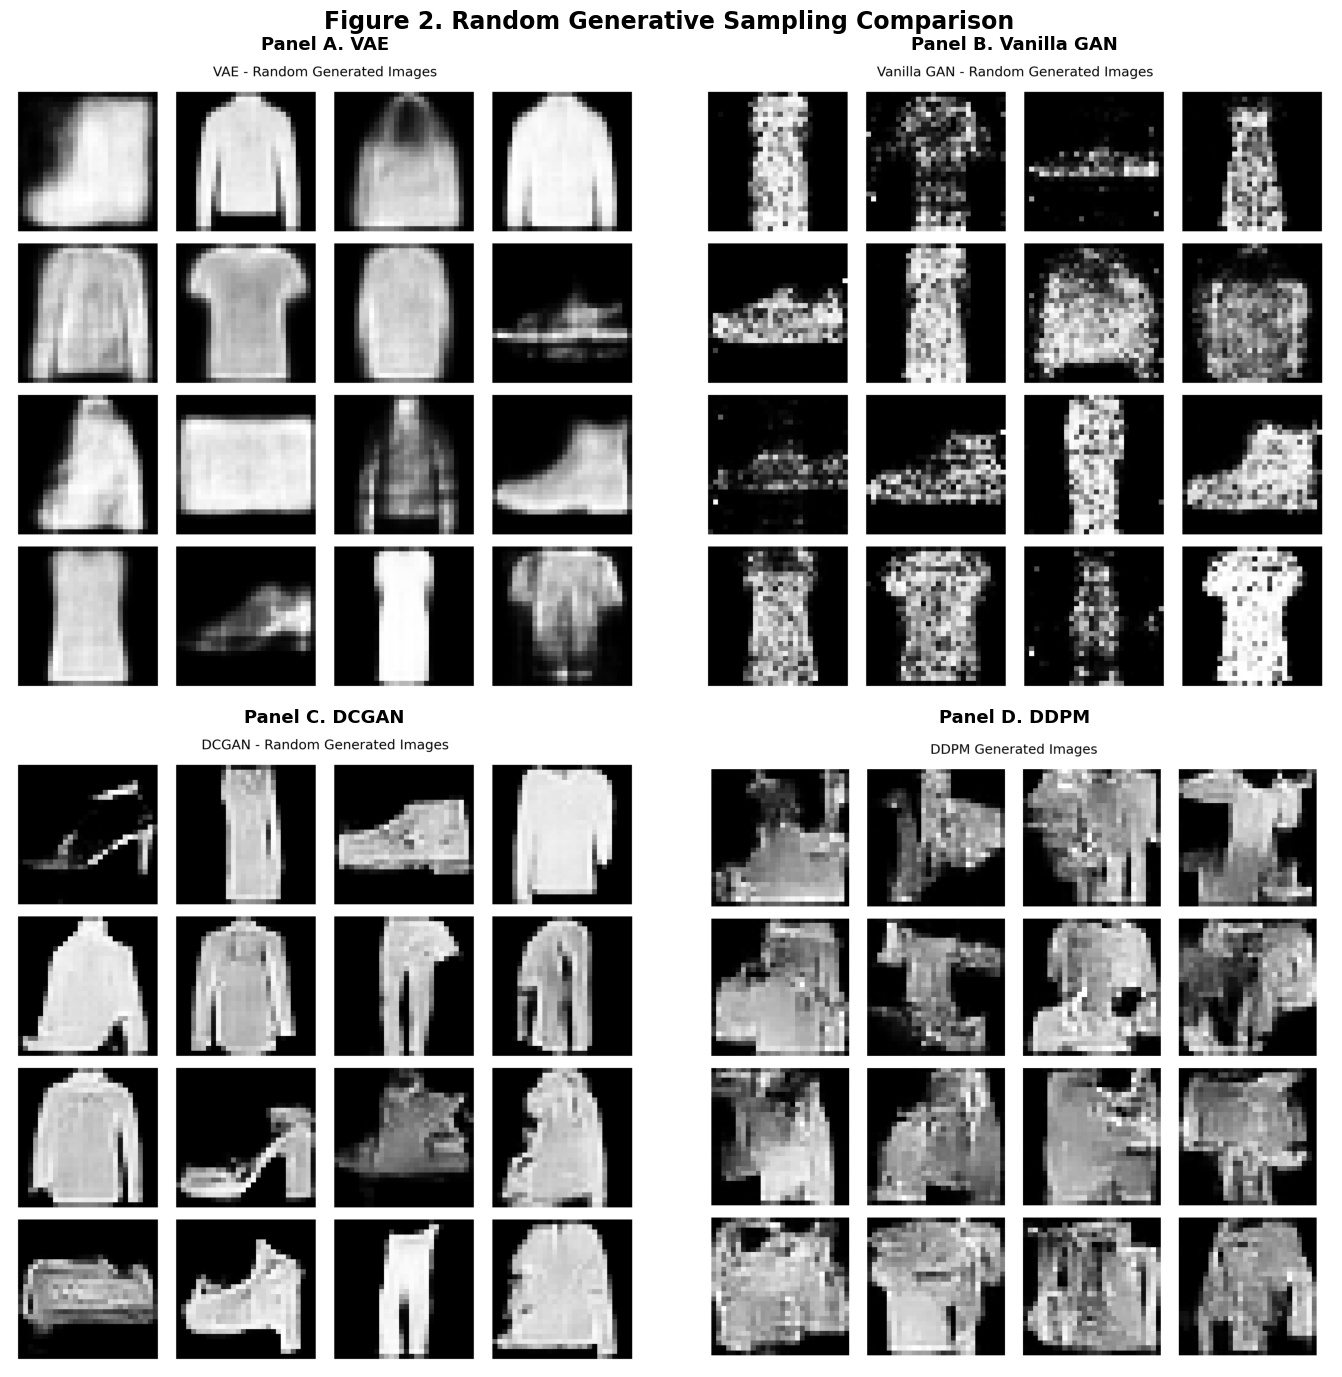

Figure 2 berhasil disimpan!
Lokasi: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/figure_2_random_generative_sampling.png


In [ ]:
figures_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures"
)

#gambar yg udh disimpen di gdrive
nama_file = [
    "vae_generated_images.png",
    "vanilla_gan_generated.png",
    "dcgan_generated.png",
    "ddpm_generated.png"
]

judul = [
    "Panel A. VAE",
    "Panel B. Vanilla GAN",
    "Panel C. DCGAN",
    "Panel D. DDPM"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 14))

for i, ax in enumerate(axes.flat):
    path_gambar = os.path.join(
        figures_path,
        nama_file[i]
    )

    gambar = plt.imread(path_gambar)
    ax.imshow(gambar)
    ax.set_title(judul[i], fontsize=13, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "Figure 2. Random Generative Sampling Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

#simpan Figure 2
output_path = os.path.join(
    figures_path,
    "figure_2_random_generative_sampling.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 berhasil disimpan!")
print("Lokasi:", output_path)

## Figure 3: Bukti Empiris Batasan MLP Classifier.

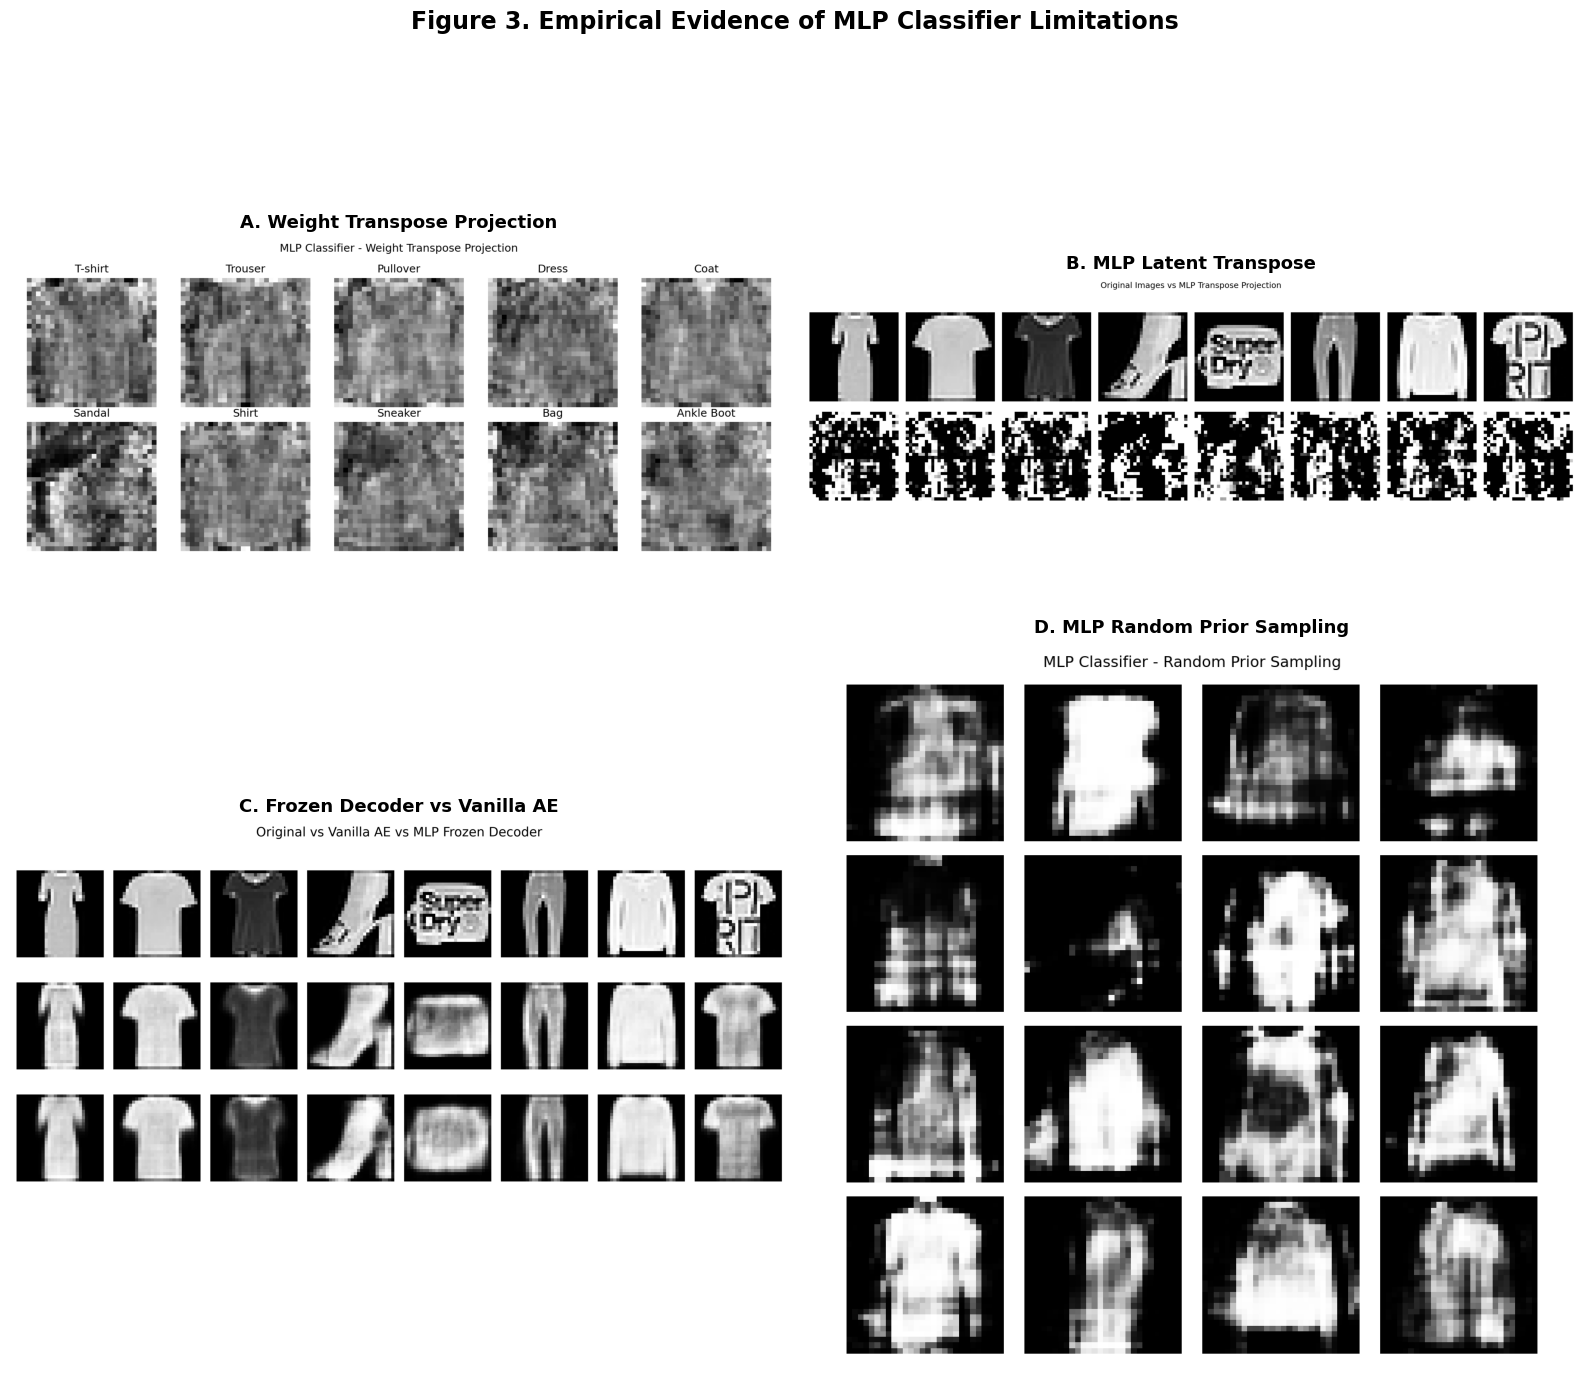

Figure 3 berhasil disimpan!
Lokasi: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/figure_3_mlp_classifier_evidence.png


In [ ]:
figures_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures"
)

nama_file = [
    "mlp_weight_transpose.png",
    "mlp_latent_transpose.png",
    "mlp_ae_decoder_comparison.png",
    "mlp_random_sampling.png"
]

judul = [
    "A. Weight Transpose Projection",
    "B. MLP Latent Transpose",
    "C. Frozen Decoder vs Vanilla AE",
    "D. MLP Random Prior Sampling"
]

for file in nama_file:
    path = os.path.join(figures_path, file)

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File tidak ditemukan: {path}"
        )

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for i, ax in enumerate(axes.flat):
    path_gambar = os.path.join(
        figures_path,
        nama_file[i]
    )
    gambar = plt.imread(path_gambar)
    ax.imshow(gambar)
    ax.set_title(
        judul[i],
        fontsize=13,
        fontweight="bold"
    )
    ax.axis("off")

plt.suptitle(
    "Figure 3. Empirical Evidence of MLP Classifier Limitations",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

#simpen Figure 3
output_path = os.path.join(
    figures_path,
    "figure_3_mlp_classifier_evidence.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 berhasil disimpan!")
print("Lokasi:", output_path)

## Figure 4 - Latent Space Interpolation Comparison

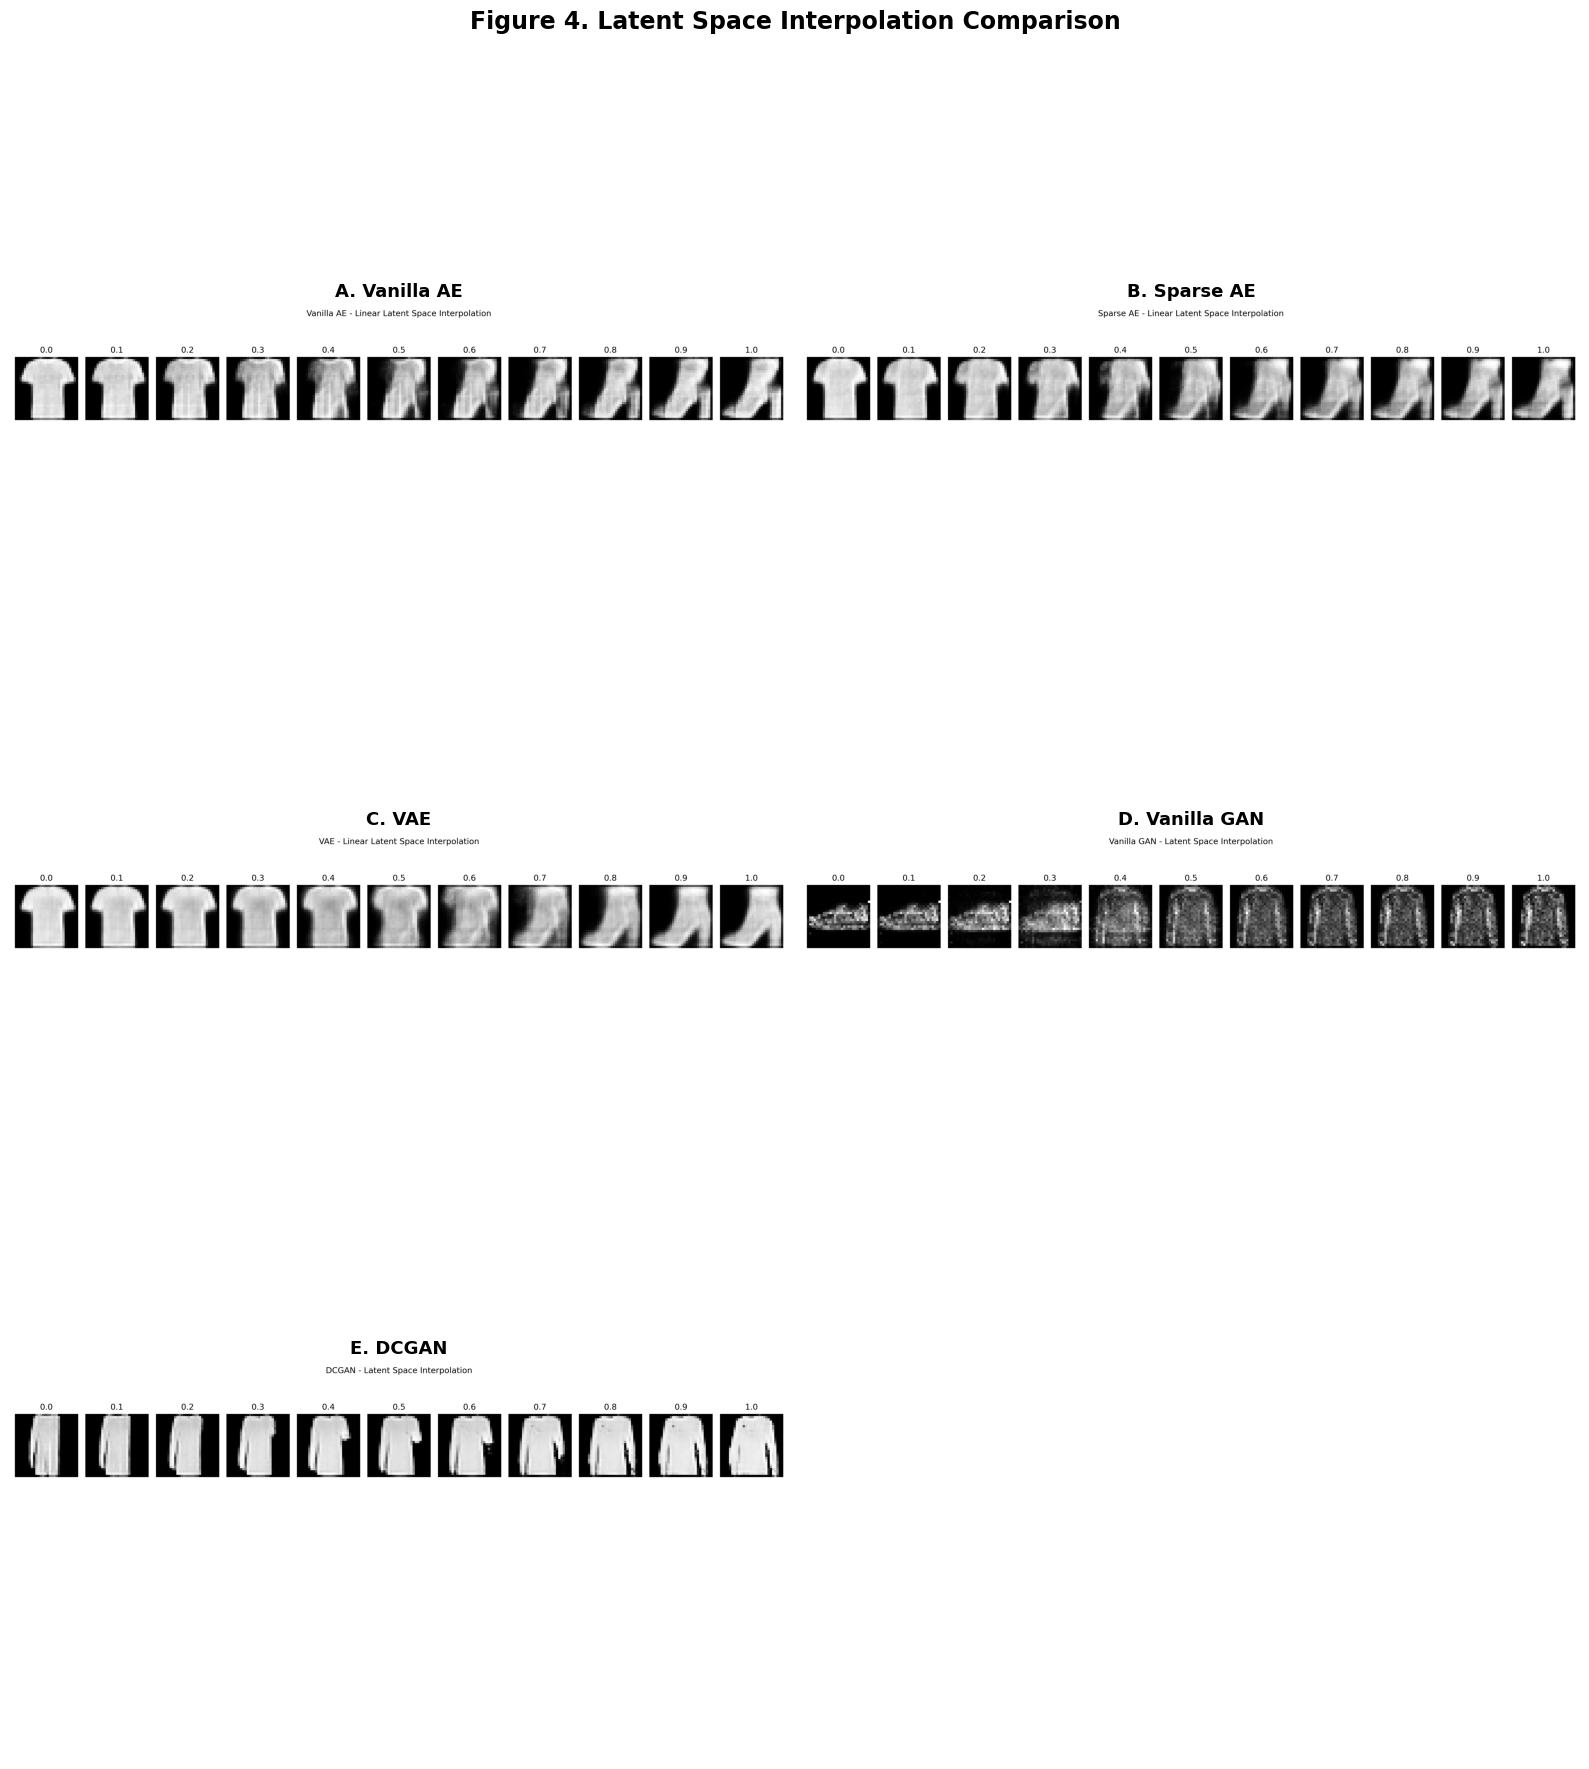

Figure 4 berhasil disimpan!
Lokasi: /content/drive/MyDrive/DeepLearning_TakeHome/results/figures/figure_4_latent_space_interpolation.png


In [ ]:
figures_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures"
)

nama_file = [
    "vanilla_ae_interpolation.png",
    "sparse_ae_interpolation.png",
    "vae_interpolation.png",
    "vanilla_gan_interpolation.png",
    "dcgan_interpolation.png"
]

judul = [
    "A. Vanilla AE",
    "B. Sparse AE",
    "C. VAE",
    "D. Vanilla GAN",
    "E. DCGAN"
]

for file in nama_file:
    path = os.path.join(figures_path, file)

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File tidak ditemukan: {path}"
        )

fig, axes = plt.subplots(3, 2, figsize=(16, 18))

for i, ax in enumerate(axes.flat):
    if i < len(nama_file):
        path_gambar = os.path.join(
            figures_path,
            nama_file[i]
        )
        gambar = plt.imread(path_gambar)
        ax.imshow(gambar)
        ax.set_title(
            judul[i],
            fontsize=13,
            fontweight="bold"
        )
        ax.axis("off")
    else:
        ax.axis("off")

plt.suptitle(
    "Figure 4. Latent Space Interpolation Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

output_path = os.path.join(
    figures_path,
    "figure_4_latent_space_interpolation.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Figure 4 berhasil disimpan!")
print("Lokasi:", output_path)

#reconnect

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, random_split, ConcatDataset
from torchvision import datasets, transforms

# Lokasi project
PROJECT_PATH = "/content/drive/MyDrive/DeepLearning_TakeHome"

# Masukkan project ke Python path
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

os.chdir(PROJECT_PATH)

# Atur device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Project:", PROJECT_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Project: /content/drive/MyDrive/DeepLearning_TakeHome


In [2]:
from src.models.autoencoder import VanillaAutoencoder
from src.models.sparse_autoencoder import SparseAutoencoder
from src.models.vae import VariationalAutoencoder
# Buat arsitektur model
LATENT_DIM = 64

autoencoder = VanillaAutoencoder(latent_dim=LATENT_DIM).to(device)
sparse_ae = SparseAutoencoder(latent_dim=LATENT_DIM).to(device)
vae_model = VariationalAutoencoder(latent_dim=LATENT_DIM).to(device)

# Lokasi checkpoint
checkpoint_path = os.path.join(PROJECT_PATH, "checkpoints")

# Load bobot model
autoencoder.load_state_dict(
    torch.load(
        os.path.join(checkpoint_path, "vanilla_ae.pth"),
        map_location=device
    )
)

sparse_ae.load_state_dict(
    torch.load(
        os.path.join(checkpoint_path, "sparse_ae.pth"),
        map_location=device
    )
)

vae_model.load_state_dict(
    torch.load(
        os.path.join(checkpoint_path, "vae.pth"),
        map_location=device
    )
)

# Evaluation mode
autoencoder.eval()
sparse_ae.eval()
vae_model.eval()

print("Vanilla AE berhasil dimuat!")
print("Sparse AE berhasil dimuat!")
print("VAE berhasil dimuat!")

Vanilla AE berhasil dimuat!
Sparse AE berhasil dimuat!
VAE berhasil dimuat!


In [3]:
# Random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Transformasi gambar
transform = transforms.ToTensor()

# Load Fashion-MNIST
train_dataset = datasets.FashionMNIST(
    root=PROJECT_PATH + "/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=PROJECT_PATH + "/data",
    train=False,
    download=True,
    transform=transform
)

# Gabungkan dataset
full_dataset = ConcatDataset([
    train_dataset,
    test_dataset
])

# Pembagian dataset 80:10:10
total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

train_set, val_set, test_set = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)

# Buat DataLoader
BATCH_SIZE = 128

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("DataLoader berhasil dibuat!")
print("Jumlah data test:", len(test_set))

DataLoader berhasil dibuat!
Jumlah data test: 7000


## cek

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DeepLearning_TakeHome"

folder_list = [
    "data",
    "checkpoints",
    "results",
    "src"
]

for folder in folder_list:
    path = os.path.join(PROJECT_PATH, folder)

    if os.path.exists(path):
        total_size = 0

        for root, dirs, files in os.walk(path):
            for file in files:
                file_path = os.path.join(root, file)
                total_size += os.path.getsize(file_path)

        print(
            folder,
            ":", round(total_size / (1024 * 1024), 2),
            "MB"
        )

data : 81.85 MB
checkpoints : 16.72 MB
results : 5.98 MB
src : 0.03 MB


In [ ]:
#masukin ke github
os.chdir(PROJECT_PATH)
!git --version
!git init

!git config user.name "alezaandria"
!git config user.email "alexabeslar82@gmail.com"

print("=== ISI PROJECT ===")
for item in sorted(os.listdir(PROJECT_PATH)):
    print(item)

!git status

git version 2.43.0
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/drive/MyDrive/DeepLearning_TakeHome/.git/
=== ISI PROJECT ===
.git
checkpoints
data
results
src
On branch master

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	checkpoints/
	data/
	results/
	src/

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
os.chdir(PROJECT_PATH)
!git remote add origin https://github.com/alezaandria/DeepLearning-TakeHome.git
!git remote -v

origin	https://github.com/alezaandria/DeepLearning-TakeHome.git (fetch)
origin	https://github.com/alezaandria/DeepLearning-TakeHome.git (push)


In [ ]:
print("=== FILE PROJECT ===")
for item in sorted(os.listdir(PROJECT_PATH)):
    print(item)

print("\n=== FILE NOTEBOOK ===")
for item in os.listdir(PROJECT_PATH):
    if item.endswith(".ipynb"):
        print(item)

print("\n=== GIT STATUS ===")
!git status --short

=== FILE PROJECT ===
.git
checkpoints
data
results
src

=== FILE NOTEBOOK ===

=== GIT STATUS ===
?? checkpoints/
?? data/
?? results/
?? src/


In [ ]:
#upload requirements
requirements_content = """
torch
torchvision
numpy
pandas
matplotlib
scikit-learn
scikit-image
tqdm
Pillow
"""

requirements_path = os.path.join(
    PROJECT_PATH,
    "requirements.txt"
)

with open(requirements_path, "w") as file:
    file.write(requirements_content.strip() + "\n")

print("requirements.txt berhasil dibuat!")

requirements.txt berhasil dibuat!


In [ ]:

readme_content = """
# Comparative Study of Generative Models

This project presents an empirical comparison of six generative models
using the Fashion-MNIST dataset. The experiments explore image
reconstruction, image generation, latent space interpolation, and
training behavior.

## Models

The following generative models are implemented and compared:

1. Vanilla Autoencoder (AE)
2. Sparse Autoencoder
3. Variational Autoencoder (VAE)
4. Vanilla Generative Adversarial Network (GAN)
5. Deep Convolutional GAN (DCGAN)
6. Denoising Diffusion Probabilistic Model (DDPM)

A Multi-Layer Perceptron (MLP) classifier is also implemented to
investigate the limitations of using a discriminative classifier
for image generation.

## Dataset

**Fashion-MNIST**

- 28 x 28 grayscale images
- 10 clothing categories
- Training, validation, and testing split: 80%, 10%, and 10%

The dataset is downloaded automatically through `torchvision`
when running the notebook.

## Experiments

The experiments cover:

- Image reconstruction using AE, Sparse AE, and VAE
- Random image generation using VAE, GAN, DCGAN, and DDPM
- Latent space interpolation
- Training loss comparison
- DDPM forward and reverse diffusion process
- MLP classifier analysis and visualization

## Project Structure

```text
DeepLearning-TakeHome/
├── checkpoints/
├── results/
├── src/
├── main.ipynb
├── requirements.txt
├── README.md
└── .gitignore
```

## Installation

Clone this repository:

```bash
git clone https://github.com/alezaandria/DeepLearning-TakeHome.git
cd DeepLearning-TakeHome
```

Install the required dependencies:

```bash
pip install -r requirements.txt
```

## How to Run

1. Open `main.ipynb` using Jupyter Notebook or Google Colab.
2. Install the required dependencies.
3. Run the notebook cells sequentially.
4. The notebook will download the Fashion-MNIST dataset if it is not
   already available.
5. Model checkpoints and experiment results are stored in their
   respective folders.

## Results

The project includes visual comparisons of:

- Image reconstruction quality
- Randomly generated samples
- Latent space interpolation
- MLP classifier evidence
- Training loss curves and DDPM denoising trajectory

The visual results are available in the `results/` directory.

## Technologies

- Python
- PyTorch
- Torchvision
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- Jupyter Notebook

## Author

Aleza Andria

## License

This project is created for educational purposes.
"""

readme_path = os.path.join(PROJECT_PATH, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README.md berhasil dibuat!")

README.md berhasil dibuat!


In [ ]:
gitignore_content = """
# Dataset
data/

# Python cache
__pycache__/
*.pyc

# Jupyter Notebook
.ipynb_checkpoints/

# Virtual environment
.venv/
venv/

# Temporary files
.DS_Store
"""

gitignore_path = os.path.join(
    PROJECT_PATH,
    ".gitignore"
)

with open(gitignore_path, "w") as file:
    file.write(gitignore_content.strip() + "\n")

print(".gitignore berhasil dibuat!")

.gitignore berhasil dibuat!


In [ ]:

os.chdir(PROJECT_PATH)

!git status --short


?? .gitignore
?? README.md
?? checkpoints/
?? main.ipynb
?? requirements.txt
?? results/
?? src/


In [ ]:
os.chdir(PROJECT_PATH)

!git add .
!git status --short

A  .gitignore
A  README.md
A  checkpoints/dcgan_discriminator.pth
A  checkpoints/dcgan_generator.pth
A  checkpoints/ddpm.pth
A  checkpoints/mlp_classifier.pth
A  checkpoints/mlp_frozen_decoder.pth
A  checkpoints/sparse_ae.pth
A  checkpoints/vae.pth
A  checkpoints/vanilla_ae.pth
A  checkpoints/vanilla_gan_discriminator.pth
A  checkpoints/vanilla_gan_generator.pth
A  main.ipynb
A  requirements.txt
A  results/figures/dcgan_generated.png
A  results/figures/dcgan_interpolation.png
A  results/figures/dcgan_loss.png
A  results/figures/ddpm_denoising_trajectory.png
A  results/figures/ddpm_forward_diffusion.png
A  results/figures/ddpm_generated.png
A  results/figures/ddpm_loss.png
A  results/figures/figure_1_reconstruction_comparison.png
A  results/figures/figure_2_random_generative_sampling.png
A  results/figures/figure_3_mlp_classifier_evidence.png
A  results/figures/figure_4_latent_space_interpolation.png
A  results/figures/figure_5_training_loss_comparison.png
A  results/figures/mlp_ae_deco

In [ ]:
!git commit -m "Add generative models experiments and results"

[master (root-commit) e5712cf] Add generative models experiments and results
 56 files changed, 97760 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 checkpoints/dcgan_discriminator.pth
 create mode 100644 checkpoints/dcgan_generator.pth
 create mode 100644 checkpoints/ddpm.pth
 create mode 100644 checkpoints/mlp_classifier.pth
 create mode 100644 checkpoints/mlp_frozen_decoder.pth
 create mode 100644 checkpoints/sparse_ae.pth
 create mode 100644 checkpoints/vae.pth
 create mode 100644 checkpoints/vanilla_ae.pth
 create mode 100644 checkpoints/vanilla_gan_discriminator.pth
 create mode 100644 checkpoints/vanilla_gan_generator.pth
 create mode 100644 main.ipynb
 create mode 100644 requirements.txt
 create mode 100644 results/figures/dcgan_generated.png
 create mode 100644 results/figures/dcgan_interpolation.png
 create mode 100644 results/figures/dcgan_loss.png
 create mode 100644 results/figures/ddpm_denoising_trajectory.png
 create mode 1

In [ ]:
!git branch -M main
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:

import os
import getpass
import subprocess

os.chdir(PROJECT_PATH)

token = getpass.getpass("Masukkan GitHub Personal Access Token: ")

# Simpan kredensial sementara untuk proses push
subprocess.run(
    ["git", "config", "--global", "credential.helper", "store"],
    check=True
)

kredensial = (
    "protocol=https\n"
    "host=github.com\n"
    "username=alezaandria\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=kredensial,
    text=True,
    check=True
)

# Push ke GitHub
hasil = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    capture_output=True,
    text=True
)

print(hasil.stdout)
print(hasil.stderr)

# Hapus kredensial dari penyimpanan setelah push
subprocess.run(
    ["git", "credential", "reject"],
    input="protocol=https\nhost=github.com\n\n",
    text=True
)

subprocess.run(
    ["git", "config", "--global", "--unset", "credential.helper"]
)

token = None


Masukkan GitHub Personal Access Token: ··········
branch 'main' set up to track 'origin/main'.

To https://github.com/alezaandria/DeepLearning-TakeHome.git
 * [new branch]      main -> main



## tambahan komparasi metrik

In [ ]:
import os
import sys
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Import arsitektur
sys.path.append(PROJECT_PATH)

from src.models.autoencoder import VanillaAutoencoder
from src.models.sparse_autoencoder import SparseAutoencoder
from src.models.vae import VariationalAutoencoder
from src.models.vanilla_gan import Generator
from src.models.dcgan import DCGANGenerator
from src.models.ddpm import DDPMModel

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Inisialisasi model
vanilla_ae = VanillaAutoencoder(latent_dim=64).to(device)
sparse_ae = SparseAutoencoder(latent_dim=64).to(device)
vae_model = VariationalAutoencoder(latent_dim=64).to(device)

gan_generator = Generator(noise_dim=100).to(device)
dcgan_generator = DCGANGenerator(noise_dim=100).to(device)

ddpm_model = DDPMModel(time_dim=64).to(device)

# Load checkpoint
vanilla_ae.load_state_dict(
    torch.load(os.path.join(PROJECT_PATH, "checkpoints/vanilla_ae.pth"),
               map_location=device)
)

sparse_ae.load_state_dict(
    torch.load(os.path.join(PROJECT_PATH, "checkpoints/sparse_ae.pth"),
               map_location=device)
)

vae_model.load_state_dict(
    torch.load(os.path.join(PROJECT_PATH, "checkpoints/vae.pth"),
               map_location=device)
)

gan_generator.load_state_dict(
    torch.load(os.path.join(PROJECT_PATH, "checkpoints/vanilla_gan_generator.pth"),
               map_location=device)
)

dcgan_generator.load_state_dict(
    torch.load(os.path.join(PROJECT_PATH, "checkpoints/dcgan_generator.pth"),
               map_location=device)
)

ddpm_model.load_state_dict(
    torch.load(os.path.join(PROJECT_PATH, "checkpoints/ddpm.pth"),
               map_location=device)
)

models = [
    vanilla_ae,
    sparse_ae,
    vae_model,
    gan_generator,
    dcgan_generator,
    ddpm_model
]

for model in models:
    model.eval()

#DDPM scheduler
T = 200
beta = torch.linspace(0.0001, 0.02, T).to(device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

alpha_bar_prev = torch.cat([
    torch.tensor([1.0], device=device),
    alpha_bar[:-1]
])

posterior_variance = (
    beta * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)
)

print("Semua model dan checkpoint berhasil dimuat!")


Device: cuda
Semua model dan checkpoint berhasil dimuat!


In [ ]:
from skimage.metrics import structural_similarity

def hitung_metrik_rekonstruksi(model, jenis_model):
    semua_mse = []
    semua_psnr = []
    semua_ssim = []

    with torch.no_grad():
        for gambar, label in eval_loader:
            gambar = gambar.to(device)
            if jenis_model == "vae":
                fitur = model.encoder(gambar)
                mu = model.fc_mu(fitur)
                hasil = model.decoder(mu)
                hasil = hasil.view(-1, 1, 28, 28)
            else:
                hasil, z = model(gambar)

            mse_per_gambar = torch.mean(
                (gambar - hasil) ** 2,
                dim=(1, 2, 3)
            )

            psnr_per_gambar = 10 * torch.log10(
                1.0 / (mse_per_gambar + 1e-10)
            )

            hasil_np = hasil.clamp(0, 1).cpu().numpy()
            gambar_np = gambar.cpu().numpy()

            semua_mse.extend(mse_per_gambar.cpu().tolist())
            semua_psnr.extend(psnr_per_gambar.cpu().tolist())

            for i in range(len(gambar_np)):
                nilai_ssim = structural_similarity(
                    gambar_np[i, 0],
                    hasil_np[i, 0],
                    data_range=1.0
                )
                semua_ssim.append(nilai_ssim)

    return {
        "Test MSE": np.mean(semua_mse),
        "Test PSNR (dB)": np.mean(semua_psnr),
        "Test SSIM": np.mean(semua_ssim)
    }


hasil_rekonstruksi = {}

hasil_rekonstruksi["Vanilla AE"] = (
    hitung_metrik_rekonstruksi(vanilla_ae, "ae")
)

hasil_rekonstruksi["Sparse AE"] = (
    hitung_metrik_rekonstruksi(sparse_ae, "ae")
)

hasil_rekonstruksi["VAE"] = (
    hitung_metrik_rekonstruksi(vae_model, "vae")
)

print("Evaluasi rekonstruksi selesai!")

for nama, metrik in hasil_rekonstruksi.items():
    print("\n", nama)
    print(metrik)

Evaluasi rekonstruksi selesai!

 Vanilla AE
{'Test MSE': np.float64(0.00969163856124838), 'Test PSNR (dB)': np.float64(21.135413678986687), 'Test SSIM': np.float64(0.7673912856205095)}

 Sparse AE
{'Test MSE': np.float64(0.011685825093549543), 'Test PSNR (dB)': np.float64(20.252559039252144), 'Test SSIM': np.float64(0.7282153998657618)}

 VAE
{'Test MSE': np.float64(0.01602164845439672), 'Test PSNR (dB)': np.float64(18.80860087789808), 'Test SSIM': np.float64(0.6792881334655553)}


In [ ]:
def sinkronisasi_device():
    if device.type == "cuda":
        torch.cuda.synchronize()

def ukur_latency(fungsi, jumlah_pengulangan=5):
    # Warm-up
    for _ in range(2):
        fungsi()
    sinkronisasi_device()
    waktu_mulai = time.perf_counter()

    for _ in range(jumlah_pengulangan):
        fungsi()
    sinkronisasi_device()
    waktu_total = time.perf_counter() - waktu_mulai
    return (waktu_total / jumlah_pengulangan) * 1000


# Input batch
gambar_latency = torch.randn(64, 1, 28, 28).to(device)
noise_vektor = torch.randn(64, 100).to(device)
noise_dcgan = torch.randn(64, 100, 1, 1).to(device)


@torch.no_grad()
def jalankan_ddpm(batch_size=64):
    gambar = torch.randn(batch_size, 1, 28, 28).to(device)

    for t in reversed(range(T)):
        waktu = torch.full(
            (batch_size,),
            t,
            device=device,
            dtype=torch.long
        )

        prediksi_noise = ddpm_model(gambar, waktu)
        gambar = (1 / torch.sqrt(alpha[t])) * (
            gambar -
            (beta[t] / torch.sqrt(1 - alpha_bar[t]))
            * prediksi_noise
        )

        if t > 0:
            noise = torch.randn_like(gambar)
            gambar = (
                gambar +
                torch.sqrt(posterior_variance[t]) * noise
            )

    return gambar


latency = {}

fungsi_latency = {
    "Vanilla AE": lambda: vanilla_ae(gambar_latency),
    "Sparse AE": lambda: sparse_ae(gambar_latency),
    "VAE": lambda: vae_model(gambar_latency),
    "Vanilla GAN": lambda: gan_generator(noise_vektor),
    "DCGAN": lambda: dcgan_generator(noise_dcgan),
    "DDPM": lambda: jalankan_ddpm(64)
}

for nama, fungsi in fungsi_latency.items():
    nilai = ukur_latency(fungsi)
    latency[nama] = nilai
    print(f"{nama}: {nilai:.2f} ms/batch")

Vanilla AE: 1.54 ms/batch
Sparse AE: 4.87 ms/batch
VAE: 5.93 ms/batch
Vanilla GAN: 0.42 ms/batch
DCGAN: 2.48 ms/batch
DDPM: 1360.47 ms/batch


In [ ]:
!pip install -q scipy scikit-image

In [ ]:
import torch.nn.functional as F
from torchvision.models import inception_v3, Inception_V3_Weights
from scipy.linalg import sqrtm

inception = inception_v3(
    weights=Inception_V3_Weights.DEFAULT
).to(device)

inception.fc = nn.Identity()
inception.eval()

mean_inception = torch.tensor(
    [0.485, 0.456, 0.406],
    device=device
).view(1, 3, 1, 1)

std_inception = torch.tensor(
    [0.229, 0.224, 0.225],
    device=device
).view(1, 3, 1, 1)

print("Inception V3 berhasil disiapkan!")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 104MB/s] 


Inception V3 berhasil disiapkan!


In [ ]:
@torch.no_grad()
def ekstrak_fitur(batch_gambar):
    # grayscale menjadi RGB
    gambar = batch_gambar.repeat(1, 3, 1, 1)
    gambar = F.interpolate(
        gambar,
        size=(299, 299),
        mode="bilinear",
        align_corners=False
    )

    # Normalisasi ImageNet
    gambar = (gambar - mean_inception) / std_inception

    fitur = inception(gambar)

    return fitur.cpu().numpy()


def kumpulkan_fitur(loader, jumlah_data):
    semua_fitur = []
    jumlah = 0

    for gambar, label in loader:
        gambar = gambar.to(device)
        fitur = ekstrak_fitur(gambar)
        semua_fitur.append(fitur)
        jumlah += len(gambar)
        if jumlah >= jumlah_data:
            break

    return np.concatenate(semua_fitur, axis=0)[:jumlah_data]


def kumpulkan_fitur_sintetis(fungsi_generate, jumlah_data):
    semua_fitur = []
    jumlah = 0

    while jumlah < jumlah_data:
        ukuran_batch = min(64, jumlah_data - jumlah)
        gambar = fungsi_generate(ukuran_batch)
        fitur = ekstrak_fitur(gambar)
        semua_fitur.append(fitur)
        jumlah += len(gambar)
    return np.concatenate(semua_fitur, axis=0)


def hitung_fid(fitur_real, fitur_fake):
    mean_real = np.mean(fitur_real, axis=0)
    mean_fake = np.mean(fitur_fake, axis=0)
    cov_real = np.cov(fitur_real, rowvar=False)
    cov_fake = np.cov(fitur_fake, rowvar=False)

    selisih_mean = mean_real - mean_fake

    hasil_sqrt = sqrtm(cov_real @ cov_fake)

    if np.iscomplexobj(hasil_sqrt):
        hasil_sqrt = hasil_sqrt.real

    fid = (
        np.sum(selisih_mean ** 2)
        + np.trace(cov_real)
        + np.trace(cov_fake)
        - 2 * np.trace(hasil_sqrt)
    )
    return float(fid)


print("Fungsi FID berhasil dibuat!")

Fungsi FID berhasil dibuat!


In [ ]:
latent_loader = DataLoader(
    train_set,
    batch_size=256,
    shuffle=False,
    num_workers=2
)


@torch.no_grad()
def buat_latent_bank(model):
    semua_latent = []

    for gambar, label in latent_loader:
        gambar = gambar.to(device)
        z = model.encoder(gambar)
        semua_latent.append(z.cpu())
    return torch.cat(semua_latent, dim=0).to(device)


latent_bank_ae = buat_latent_bank(vanilla_ae)
latent_bank_sparse = buat_latent_bank(sparse_ae)

print("Latent bank Vanilla AE:", latent_bank_ae.shape)
print("Latent bank Sparse AE:", latent_bank_sparse.shape)

Latent bank Vanilla AE: torch.Size([56000, 64])
Latent bank Sparse AE: torch.Size([56000, 64])


In [ ]:
@torch.no_grad()
def generate_ae(batch_size):
    indeks = torch.randint(
        0, len(latent_bank_ae), (batch_size,)
    )
    z = latent_bank_ae[indeks]
    hasil = vanilla_ae.decoder(z)
    return hasil.view(-1, 1, 28, 28).clamp(0, 1)

@torch.no_grad()
def generate_sparse_ae(batch_size):
    indeks = torch.randint(
        0, len(latent_bank_sparse), (batch_size,)
    )
    z = latent_bank_sparse[indeks]
    hasil = sparse_ae.decoder(z)
    return hasil.view(-1, 1, 28, 28).clamp(0, 1)

@torch.no_grad()
def generate_vae_fid(batch_size):
    z = torch.randn(batch_size, 64, device=device)
    hasil = vae_model.decoder(z)
    hasil = hasil.view(-1, 1, 28, 28)
    return hasil.clamp(0, 1)

@torch.no_grad()
def generate_gan_fid(batch_size):
    z = torch.randn(batch_size, 100, device=device)
    hasil = gan_generator(z)
    return ((hasil + 1) / 2).clamp(0, 1)

@torch.no_grad()
def generate_dcgan_fid(batch_size):
    z = torch.randn(batch_size, 100, 1, 1, device=device)
    hasil = dcgan_generator(z)
    return ((hasil + 1) / 2).clamp(0, 1)

@torch.no_grad()
def generate_ddpm_fid(batch_size):
    gambar = torch.randn(
        batch_size, 1, 28, 28, device=device
    )
    for t in reversed(range(T)):
        waktu = torch.full(
            (batch_size,),
            t,
            device=device,
            dtype=torch.long
        )
        prediksi_noise = ddpm_model(gambar, waktu)
        gambar = (1 / torch.sqrt(alpha[t])) * (
            gambar -
            (beta[t] / torch.sqrt(1 - alpha_bar[t]))
            * prediksi_noise
        )

        if t > 0:
            noise = torch.randn_like(gambar)
            gambar = (
                gambar +
                torch.sqrt(posterior_variance[t]) * noise
            )
    return gambar.clamp(0, 1)

print("Semua fungsi sampling berhasil dibuat!")

Semua fungsi sampling berhasil dibuat!


In [ ]:
JUMLAH_FID = 5000

# Fitur gambar asli
print("Menghitung fitur gambar test...")

fitur_real = kumpulkan_fitur(
    eval_loader,
    JUMLAH_FID
)

print("Fitur gambar asli:", fitur_real.shape)

# Fungsi sampling masing-masing model
fungsi_fid = {
    "Vanilla AE": generate_ae,
    "Sparse AE": generate_sparse_ae,
    "VAE": generate_vae_fid,
    "Vanilla GAN": generate_gan_fid,
    "DCGAN": generate_dcgan_fid,
    "DDPM": generate_ddpm_fid
}

hasil_fid = {}

for nama, fungsi in fungsi_fid.items():
    print(f"\nMenghitung FID {nama}...")

    fitur_fake = kumpulkan_fitur_sintetis(
        fungsi,
        JUMLAH_FID
    )

    nilai_fid = hitung_fid(
        fitur_real,
        fitur_fake
    )

    hasil_fid[nama] = nilai_fid
    print(f"FID {nama}: {nilai_fid:.4f}")
print("\nSemua perhitungan FID selesai!")

Menghitung fitur gambar test...
Fitur gambar asli: (5000, 2048)

Menghitung FID Vanilla AE...
FID Vanilla AE: 56.0086

Menghitung FID Sparse AE...
FID Sparse AE: 66.6301

Menghitung FID VAE...
FID VAE: 84.2233

Menghitung FID Vanilla GAN...
FID Vanilla GAN: 156.8055

Menghitung FID DCGAN...
FID DCGAN: 24.6397

Menghitung FID DDPM...
FID DDPM: 164.1601

Semua perhitungan FID selesai!


In [ ]:
folder_metrics = os.path.join(
   PROJECT_PATH,
    "results",
    "metrics"
)

os.makedirs(folder_metrics, exist_ok=True)

fid_df = pd.DataFrame({
    "Model": list(hasil_fid.keys()),
    "FID Score": list(hasil_fid.values())
})

fid_df.to_csv(
    os.path.join(folder_metrics, "fid_scores.csv"),
    index=False
)

print(fid_df.to_string(index=False))
print("\nFID berhasil disimpan!")

      Model  FID Score
 Vanilla AE  56.008581
  Sparse AE  66.630123
        VAE  84.223301
Vanilla GAN 156.805523
      DCGAN  24.639709
       DDPM 164.160082

FID berhasil disimpan!
